In [108]:
# ==========================================
# SEPSISHIELD - DATA PREPROCESSING
# Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Display settings
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [109]:
# ==========================================
# CONNECT GOOGLE DRIVE
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!


In [110]:
# ==========================================
# CHECK DATASET LOCATION
# ==========================================

FOLDER_PATH = "/content/drive/MyDrive/SepsisShield_Phase2"

print("Files available in project folder:\n")

if os.path.exists(FOLDER_PATH):

    for file in os.listdir(FOLDER_PATH):
        print(file)

else:
    print("Project folder not found!")

Files available in project folder:

Copy of Copy of Dataset_Sepsis.csv
Copy of Dataset_Sepsis.csv
outputs
Copy of 02_Data_Preprocessing.ipynb
Copy of 01_EDA.ipynb


In [111]:
# ==========================================
# LOAD ORIGINAL DATASET
# ==========================================

DATA_PATH = os.path.join(
    FOLDER_PATH,
    "Copy of Dataset_Sepsis.csv"
)

df = pd.read_csv(
    DATA_PATH,
    dtype={"Patient_ID": str}
)

print("Dataset loaded successfully!")

print("\nDataset Shape:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

print("Unique Patients:", df["Patient_ID"].nunique())

Dataset loaded successfully!

Dataset Shape: (1552210, 44)
Total Rows: 1552210
Total Columns: 44
Unique Patients: 40336


In [112]:
# ==========================================
# DISPLAY FIRST FIVE RECORDS
# ==========================================

df.head()

,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,FiO2,pH,PaCO2,SaO2,AST,BUN,Alkalinephos,Calcium,Chloride,Creatinine,Bilirubin_direct,Glucose,Lactate,Magnesium,Phosphate,Potassium,Bilirubin_total,TroponinI,Hct,Hgb,PTT,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,017072
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,NaN,NaN,0.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,017072
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,017072
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,017072
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,NaN,26.0,0.4,NaN,NaN,NaN,NaN,23.0,NaN,9.6,104.0,0.8,NaN,161.0,NaN,1.6,2.1,3.2,NaN,NaN,29.7,9.5,30.6,11.3,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,017072


In [113]:
## 2. Data Quality Inspection

'''In this section, we investigate the quality and consistency
of the original ICU dataset.

The inspection includes:

1. Dataset structure and data types.
2. Missing-value identification.
3. Duplicate record detection.
4. Patient-hour consistency.
5. Redundant column investigation.
6. Invalid and inconsistent observations.

The original dataset will remain unchanged throughout
the inspection process.'''

'In this section, we investigate the quality and consistency\nof the original ICU dataset.\n\nThe inspection includes:\n\n1. Dataset structure and data types.\n2. Missing-value identification.\n3. Duplicate record detection.\n4. Patient-hour consistency.\n5. Redundant column investigation.\n6. Invalid and inconsistent observations.\n\nThe original dataset will remain unchanged throughout\nthe inspection process.'

In [114]:
# ==========================================
# STEP 7: DATASET STRUCTURE INSPECTION
# ==========================================

print("DATASET STRUCTURE")
print("=" * 50)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nDataset Information:")
df.info()

DATASET STRUCTURE
Number of Rows: 1552210
Number of Columns: 44

Column Names:
['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel', 'Patient_ID']

Data Types:


,Data Type
Unnamed: 0,int64
Hour,int64
HR,float64
O2Sat,float64
Temp,float64
SBP,float64
MAP,float64
DBP,float64
Resp,float64
EtCO2,float64



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1552210 entries, 0 to 1552209
Data columns (total 44 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   Unnamed: 0        1552210 non-null  int64  
 1   Hour              1552210 non-null  int64  
 2   HR                1398811 non-null  float64
 3   O2Sat             1349474 non-null  float64
 4   Temp              525226 non-null   float64
 5   SBP               1325945 non-null  float64
 6   MAP               1358940 non-null  float64
 7   DBP               1065656 non-null  float64
 8   Resp              1313875 non-null  float64
 9   EtCO2             57636 non-null    float64
 10  BaseExcess        84145 non-null    float64
 11  HCO3              65028 non-null    float64
 12  FiO2              129365 non-null   float64
 13  pH                107573 non-null   float64
 14  PaCO2             86301 non-null    float64
 15  SaO2              53561 non

In [115]:
# ==========================================
# STEP 8: MISSING VALUE INSPECTION
# ==========================================

missing_report = pd.DataFrame({

    "Missing_Count": df.isnull().sum(),

    "Available_Count": df.notnull().sum(),

    "Missing_Percentage": df.isnull().mean() * 100

})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report)

,Missing_Count,Available_Count,Missing_Percentage
Bilirubin_direct,1549220,2990,99.807371
Fibrinogen,1541968,10242,99.340167
TroponinI,1537429,14781,99.047745
Bilirubin_total,1529069,23141,98.509158
Alkalinephos,1527269,24941,98.393194
AST,1527027,25183,98.377604
Lactate,1510764,41446,97.329872
PTT,1506511,45699,97.055875
SaO2,1498649,53561,96.549372
EtCO2,1494574,57636,96.286843


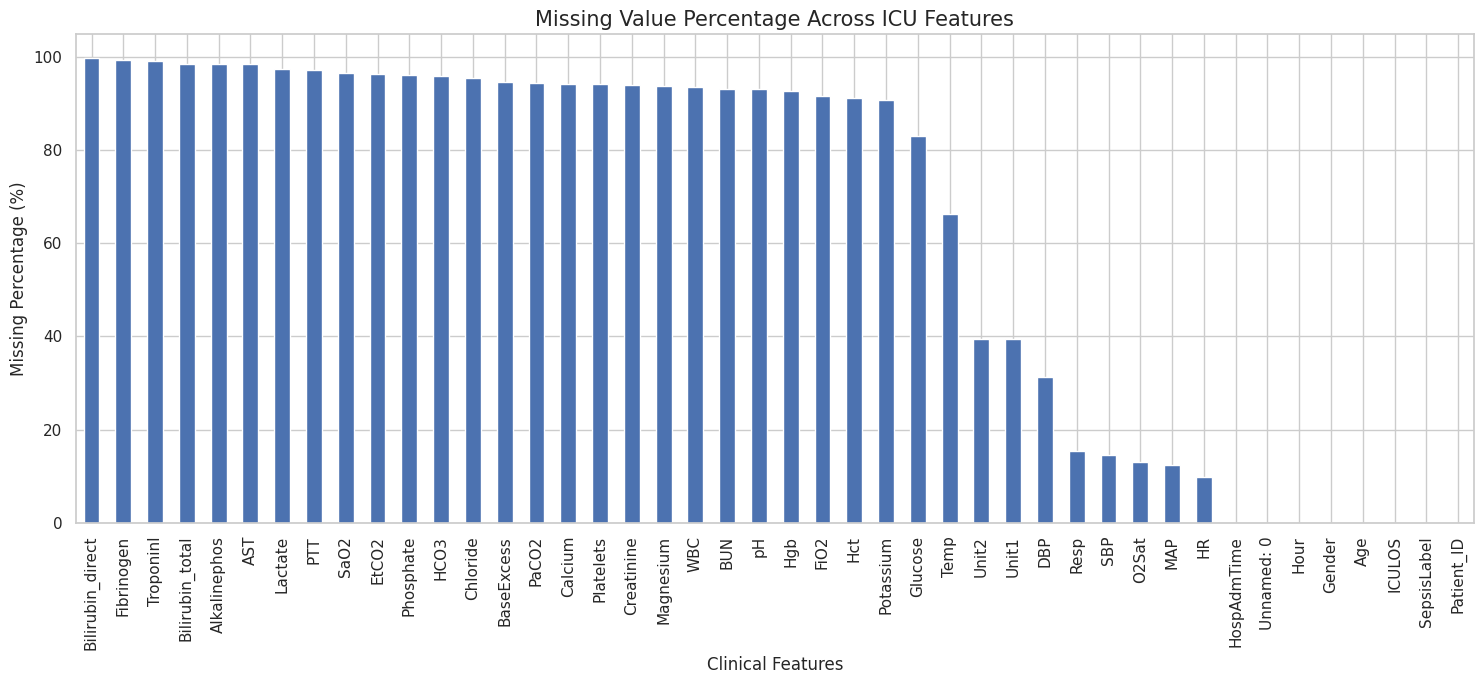

In [116]:
# ==========================================
# MISSING VALUE VISUALIZATION
# ==========================================

plt.figure(figsize=(15, 7))

missing_report["Missing_Percentage"].plot(
    kind="bar"
)

plt.title(
    "Missing Value Percentage Across ICU Features",
    fontsize=15
)

plt.xlabel("Clinical Features")
plt.ylabel("Missing Percentage (%)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

In [117]:
# ==========================================
# STEP 9: COMPLETE DUPLICATE INSPECTION
# ==========================================

complete_duplicates = df.duplicated().sum()

print("Complete Duplicate Records:",
      complete_duplicates)

print("Percentage of Duplicate Records:",
      (complete_duplicates / len(df)) * 100)

Complete Duplicate Records: 0
Percentage of Duplicate Records: 0.0


In [118]:
# ==========================================
# DUPLICATE PATIENT-HOUR INSPECTION
# ==========================================

patient_hour_duplicates = df.duplicated(
    subset=["Patient_ID", "ICULOS"]
).sum()

print(
    "Duplicate Patient-Hour Combinations:",
    patient_hour_duplicates
)

Duplicate Patient-Hour Combinations: 0


In [119]:
# ==========================================
# INVESTIGATE DUPLICATE PATIENT-HOUR RECORDS
# ==========================================

duplicate_rows = df[
    df.duplicated(
        subset=["Patient_ID", "ICULOS"],
        keep=False
    )
].sort_values(
    ["Patient_ID", "ICULOS"]
)

print("Total Rows Involved in Duplicate Patient-Hour Groups:",
      len(duplicate_rows))

display(duplicate_rows.head(20))

Total Rows Involved in Duplicate Patient-Hour Groups: 0


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,FiO2,pH,PaCO2,SaO2,AST,BUN,Alkalinephos,Calcium,Chloride,Creatinine,Bilirubin_direct,Glucose,Lactate,Magnesium,Phosphate,Potassium,Bilirubin_total,TroponinI,Hct,Hgb,PTT,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID


In [120]:
# ==========================================
# STEP 11: REDUNDANT COLUMN INSPECTION
# ==========================================

unnamed_columns = [
    col for col in df.columns
    if col.startswith("Unnamed")
]

print("Potential Redundant Columns:",
      unnamed_columns)

for col in unnamed_columns:

    print("\nColumn:", col)

    print("Data Type:", df[col].dtype)

    print("Unique Values:", df[col].nunique())

    print("Sample Values:")

    display(df[col].head(10))

Potential Redundant Columns: ['Unnamed: 0']

Column: Unnamed: 0
Data Type: int64
Unique Values: 336
Sample Values:


,Unnamed: 0
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [121]:
# ==========================================
# STEP 12: IMPORTANT COLUMN VALIDATION
# ==========================================

print("PATIENT_ID VALIDATION")

print("Missing Patient IDs:",
      df["Patient_ID"].isnull().sum())

print("Unique Patients:",
      df["Patient_ID"].nunique())


print("\nICULOS VALIDATION")

print("Missing ICULOS:",
      df["ICULOS"].isnull().sum())

print("Minimum ICULOS:",
      df["ICULOS"].min())

print("Maximum ICULOS:",
      df["ICULOS"].max())


print("\nSEPSIS LABEL VALIDATION")

print("Missing Sepsis Labels:",
      df["SepsisLabel"].isnull().sum())

print("Unique Sepsis Labels:",
      df["SepsisLabel"].unique())

print("\nSepsis Label Distribution:")

display(df["SepsisLabel"].value_counts(dropna=False))

PATIENT_ID VALIDATION
Missing Patient IDs: 0
Unique Patients: 40336

ICULOS VALIDATION
Missing ICULOS: 0
Minimum ICULOS: 1
Maximum ICULOS: 336

SEPSIS LABEL VALIDATION
Missing Sepsis Labels: 0
Unique Sepsis Labels: [0 1]

Sepsis Label Distribution:


,count
SepsisLabel,
0,1524294
1,27916


In [122]:
# ==========================================
# STEP 13: DATA QUALITY SUMMARY
# ==========================================

quality_summary = pd.DataFrame({

    "Metric": [
        "Total Rows",
        "Total Columns",
        "Unique Patients",
        "Total Missing Values",
        "Complete Duplicate Rows",
        "Duplicate Patient-Hour Groups",
        "Missing Patient IDs",
        "Missing ICU Hours",
        "Missing Sepsis Labels"
    ],

    "Value": [

        len(df),

        len(df.columns),

        df["Patient_ID"].nunique(),

        df.isnull().sum().sum(),

        complete_duplicates,

        patient_hour_duplicates,

        df["Patient_ID"].isnull().sum(),

        df["ICULOS"].isnull().sum(),

        df["SepsisLabel"].isnull().sum()

    ]

})

display(quality_summary)

,Metric,Value
0,Total Rows,1552210
1,Total Columns,44
2,Unique Patients,40336
3,Total Missing Values,43512155
4,Complete Duplicate Rows,0
5,Duplicate Patient-Hour Groups,0
6,Missing Patient IDs,0
7,Missing ICU Hours,0
8,Missing Sepsis Labels,0


In [123]:
# ==========================================
# SAVE DATA QUALITY REPORTS
# ==========================================

OUTPUT_PATH = (
    "/content/drive/MyDrive/SepsisShield_Phase2/"
    "outputs/preprocessing"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

missing_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "missing_value_analysis.csv"
    )
)

quality_summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "data_quality_summary.csv"
    ),
    index=False
)

duplicate_rows.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "duplicate_patient_hour_records.csv"
    ),
    index=False
)

print("Data quality reports saved successfully!")

Data quality reports saved successfully!


In [124]:
# ==========================================
# MOST AND LEAST AVAILABLE FEATURES
# ==========================================

print("TOP 10 MOST MISSING FEATURES")

display(
    missing_report.head(10)
)

print("\nTOP 10 LEAST MISSING FEATURES")

display(
    missing_report.sort_values(
        "Missing_Percentage",
        ascending=True
    ).head(10)
)

TOP 10 MOST MISSING FEATURES


,Missing_Count,Available_Count,Missing_Percentage
Bilirubin_direct,1549220,2990,99.807371
Fibrinogen,1541968,10242,99.340167
TroponinI,1537429,14781,99.047745
Bilirubin_total,1529069,23141,98.509158
Alkalinephos,1527269,24941,98.393194
AST,1527027,25183,98.377604
Lactate,1510764,41446,97.329872
PTT,1506511,45699,97.055875
SaO2,1498649,53561,96.549372
EtCO2,1494574,57636,96.286843



TOP 10 LEAST MISSING FEATURES


,Missing_Count,Available_Count,Missing_Percentage
Age,0,1552210,0.000000
ICULOS,0,1552210,0.000000
SepsisLabel,0,1552210,0.000000
Patient_ID,0,1552210,0.000000
Gender,0,1552210,0.000000
Unnamed: 0,0,1552210,0.000000
Hour,0,1552210,0.000000
HospAdmTime,8,1552202,0.000515
HR,153399,1398811,9.882619
MAP,193270,1358940,12.451279


In [125]:
# ==========================================
# SEPSIS LABEL DISTRIBUTION
# ==========================================

label_counts = df["SepsisLabel"].value_counts()

print("Sepsis Label Distribution:")

display(label_counts)

print("\nPercentage Distribution:")

display(
    df["SepsisLabel"].value_counts(
        normalize=True
    ) * 100
)

Sepsis Label Distribution:


,count
SepsisLabel,
0,1524294
1,27916



Percentage Distribution:


,proportion
SepsisLabel,
0,98.201532
1,1.798468


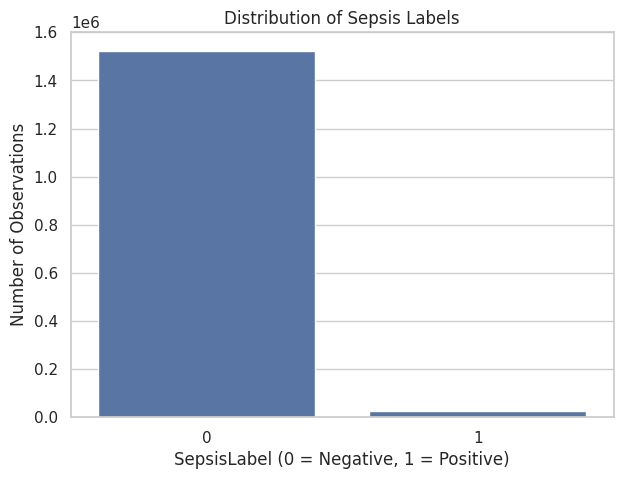

In [126]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="SepsisLabel"
)

plt.title("Distribution of Sepsis Labels")

plt.xlabel("SepsisLabel (0 = Negative, 1 = Positive)")

plt.ylabel("Number of Observations")

plt.show()

In [127]:
# ==========================================
# REDUNDANT COLUMN INVESTIGATION
# ==========================================

print("ALL DATASET COLUMNS:\n")

for i, col in enumerate(df.columns, start=1):

    print(i, "-", col)

ALL DATASET COLUMNS:

1 - Unnamed: 0
2 - Hour
3 - HR
4 - O2Sat
5 - Temp
6 - SBP
7 - MAP
8 - DBP
9 - Resp
10 - EtCO2
11 - BaseExcess
12 - HCO3
13 - FiO2
14 - pH
15 - PaCO2
16 - SaO2
17 - AST
18 - BUN
19 - Alkalinephos
20 - Calcium
21 - Chloride
22 - Creatinine
23 - Bilirubin_direct
24 - Glucose
25 - Lactate
26 - Magnesium
27 - Phosphate
28 - Potassium
29 - Bilirubin_total
30 - TroponinI
31 - Hct
32 - Hgb
33 - PTT
34 - WBC
35 - Fibrinogen
36 - Platelets
37 - Age
38 - Gender
39 - Unit1
40 - Unit2
41 - HospAdmTime
42 - ICULOS
43 - SepsisLabel
44 - Patient_ID


In [128]:
# Check columns containing Unnamed

unnamed_columns = [
    col for col in df.columns
    if "Unnamed" in col
]

print("Unnamed Columns:", unnamed_columns)

Unnamed Columns: ['Unnamed: 0']


In [129]:
# 3. Missing Value Handling

'''Missing values are common in ICU datasets because clinical
measurements are not necessarily recorded every hour.

In this section, we investigate different missing-value
handling strategies to understand their impact on the dataset.

The following experiments will be performed:

1. Original missing observations.
2. Median imputation.
3. Limited forward filling (maximum 3 hours).

We will also investigate missingness indicators to preserve
information about unavailable clinical measurements.

Patient_ID, ICULOS and SepsisLabel will never be imputed.'''

'Missing values are common in ICU datasets because clinical\nmeasurements are not necessarily recorded every hour.\n\nIn this section, we investigate different missing-value\nhandling strategies to understand their impact on the dataset.\n\nThe following experiments will be performed:\n\n1. Original missing observations.\n2. Median imputation.\n3. Limited forward filling (maximum 3 hours).\n\nWe will also investigate missingness indicators to preserve\ninformation about unavailable clinical measurements.\n\nPatient_ID, ICULOS and SepsisLabel will never be imputed.'

In [130]:
# ==========================================
# STEP 19: IDENTIFY CLINICAL FEATURES
# ==========================================

# Continuous clinical measurements
clinical_features = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP",
    "Resp", "EtCO2", "BaseExcess", "HCO3", "FiO2",
    "pH", "PaCO2", "SaO2", "AST", "BUN",
    "Alkalinephos", "Calcium", "Chloride",
    "Creatinine", "Bilirubin_direct", "Glucose",
    "Lactate", "Magnesium", "Phosphate",
    "Potassium", "Bilirubin_total", "Troponin",
    "Hct", "Hgb", "PTT", "WBC",
    "Fibrinogen", "Platelets"
]

# Keep only columns actually present in the dataset
clinical_features = [
    col for col in clinical_features
    if col in df.columns
]

print("Total Clinical Features:",
      len(clinical_features))

print("\nClinical Features:")

print(clinical_features)

Total Clinical Features: 33

Clinical Features:
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets']


In [131]:
## Experiment A – Original Missing Observations

'''The original dataset is used as the baseline.

No missing values are filled or removed.

This experiment helps us understand the original missingness
before applying any preprocessing technique.'''

'The original dataset is used as the baseline.\n\nNo missing values are filled or removed.\n\nThis experiment helps us understand the original missingness\nbefore applying any preprocessing technique.'

In [132]:
# ==========================================
# EXPERIMENT A: ORIGINAL MISSING VALUES
# ==========================================

original_missing = df[clinical_features].isnull().sum()

original_missing_percentage = (
    df[clinical_features].isnull().mean() * 100
)

original_report = pd.DataFrame({

    "Missing_Count": original_missing,

    "Missing_Percentage": original_missing_percentage

})

display(
    original_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

print(
    "\nTotal Original Clinical Missing Values:",
    original_missing.sum()
)

,Missing_Count,Missing_Percentage
Bilirubin_direct,1549220,99.807371
Fibrinogen,1541968,99.340167
Bilirubin_total,1529069,98.509158
Alkalinephos,1527269,98.393194
AST,1527027,98.377604
Lactate,1510764,97.329872
PTT,1506511,97.055875
SaO2,1498649,96.549372
EtCO2,1494574,96.286843
Phosphate,1489909,95.986303



Total Original Clinical Missing Values: 40750798


In [133]:
## Experiment B – Median Imputation

'''Median imputation replaces missing clinical measurements
with the median value of the corresponding feature.

The median is used because it is less sensitive to extreme
observations than the mean.

This experiment is performed to compare statistical
imputation with the original missing observations.

The imputed values will be stored separately.
The original dataset will remain unchanged.'''
# ==========================================
# EXPERIMENT B: MEDIAN IMPUTATION
# ==========================================

# Calculate median for each clinical feature
feature_medians = df[clinical_features].median()

# Create a separate experiment dataset
median_df = df[clinical_features].copy()

# Apply median imputation
median_df = median_df.fillna(feature_medians)

print("Median imputation experiment completed!")

print(
    "\nMissing Values Before:",
    df[clinical_features].isnull().sum().sum()
)

print(
    "Missing Values After:",
    median_df.isnull().sum().sum()
)



Median imputation experiment completed!

Missing Values Before: 40750798
Missing Values After: 0


In [134]:
'''## Experiment C – Limited Forward Filling

Forward filling uses the most recent available observation
to fill subsequent missing values.

In this experiment:

1. Data is sorted by Patient_ID and ICULOS.
2. Forward filling is performed separately for each patient.
3. A maximum limit of three consecutive missing observations
   is applied.
4. Future observations are never used.
5. Patient_ID, ICULOS and SepsisLabel are excluded.

This approach investigates whether recent clinical
measurements can help address short-term missingness.'''

# ==========================================
# EXPERIMENT C: LIMITED FORWARD FILLING
# ==========================================

# Create a separate dataset
ffill_df = df[
    ["Patient_ID", "ICULOS"] + clinical_features
].copy()

# Sort observations chronologically
ffill_df = ffill_df.sort_values(
    ["Patient_ID", "ICULOS"]
)

# Forward fill within each patient
ffill_df[clinical_features] = (
    ffill_df.groupby("Patient_ID")[clinical_features]
    .ffill(limit=3)
)

print("Limited forward filling completed!")

print(
    "\nOriginal Missing Values:",
    df[clinical_features].isnull().sum().sum()
)

print(
    "Missing Values After Forward Filling:",
    ffill_df[clinical_features].isnull().sum().sum()
)

Limited forward filling completed!

Original Missing Values: 40750798
Missing Values After Forward Filling: 34502779


In [135]:
## Comparison of Missing Value Handling Techniques

'''The original dataset, median-imputed dataset and
forward-filled dataset are compared.

The objective is to measure how effectively each technique
reduces missing observations.

The comparison will help guide the final preprocessing
strategy.'''

# ==========================================
# STEP 23: MISSING VALUE COMPARISON
# ==========================================

missing_comparison = pd.DataFrame({

    "Original": [
        df[clinical_features].isnull().sum().sum()
    ],

    "Median Imputation": [
        median_df.isnull().sum().sum()
    ],

    "Forward Filling": [
        ffill_df[clinical_features].isnull().sum().sum()
    ]

}, index=["Total Missing Values"])

display(missing_comparison)

,Original,Median Imputation,Forward Filling
Total Missing Values,40750798,0,34502779


In [136]:
# ==========================================
# STEP 24: MISSINGNESS INDICATORS
# ==========================================

missing_indicators = pd.DataFrame(
    index=df.index
)

for col in clinical_features:

    missing_indicators[col + "_Missing"] = (
        df[col].isnull().astype("int8")
    )

print("Missingness indicators created!")

print(
    "Number of Missingness Indicator Columns:",
    len(missing_indicators.columns)
)

display(missing_indicators.head())

Missingness indicators created!
Number of Missingness Indicator Columns: 33


,HR_Missing,O2Sat_Missing,Temp_Missing,SBP_Missing,MAP_Missing,DBP_Missing,Resp_Missing,EtCO2_Missing,BaseExcess_Missing,HCO3_Missing,FiO2_Missing,pH_Missing,PaCO2_Missing,SaO2_Missing,AST_Missing,BUN_Missing,Alkalinephos_Missing,Calcium_Missing,Chloride_Missing,Creatinine_Missing,Bilirubin_direct_Missing,Glucose_Missing,Lactate_Missing,Magnesium_Missing,Phosphate_Missing,Potassium_Missing,Bilirubin_total_Missing,Hct_Missing,Hgb_Missing,PTT_Missing,WBC_Missing,Fibrinogen_Missing,Platelets_Missing
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
1,0,0,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
2,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
3,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
4,0,0,1,0,0,0,0,1,1,0,0,1,1,1,1,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0


In [137]:
indicator_summary = pd.DataFrame({

    "Originally_Missing": missing_indicators.sum(),

    "Missing_Percentage": (
        missing_indicators.mean() * 100
    )

})

display(
    indicator_summary.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Originally_Missing,Missing_Percentage
Bilirubin_direct_Missing,1549220,99.807371
Fibrinogen_Missing,1541968,99.340167
Bilirubin_total_Missing,1529069,98.509158
Alkalinephos_Missing,1527269,98.393194
AST_Missing,1527027,98.377604
Lactate_Missing,1510764,97.329872
PTT_Missing,1506511,97.055875
SaO2_Missing,1498649,96.549372
EtCO2_Missing,1494574,96.286843
Phosphate_Missing,1489909,95.986303


In [138]:
# ==========================================
# STEP 25: SAVE EXPERIMENT RESULTS
# ==========================================

OUTPUT_PATH = (
    "/content/drive/MyDrive/SepsisShield_Phase2/"
    "outputs/preprocessing"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

original_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "experiment_A_original_missingness.csv"
    )
)

missing_comparison.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "missingness_comparison.csv"
    )
)

indicator_summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "missingness_indicator_summary.csv"
    )
)

print("Missing value experiment reports saved successfully!")

Missing value experiment reports saved successfully!


In [139]:
# 4. Inconsistent Data Handling and Clinical Value Validation
'''In this section, we investigate the consistency and validity
of clinical measurements in the original ICU dataset.

The analysis includes:

1. Numerical data type validation.
2. Detection of infinite values.
3. Clinical measurement range validation.
4. Investigation of negative and suspicious values.
5. SepsisLabel validation.
6. Patient timeline consistency checks.

The objective is to identify potentially invalid observations
without unnecessarily removing clinically meaningful
extreme measurements.

All investigations will be performed on a separate analysis
copy. The original dataset will remain unchanged.'''

# ==========================================
# STEP 27: NUMERICAL DATA TYPE VALIDATION
# ==========================================

# Create a separate inspection copy
validation_df = df.copy()

# Important identifiers and target columns
protected_columns = [
    "Patient_ID",
    "ICULOS",
    "SepsisLabel"
]

# Identify clinical numerical columns
numeric_features = [
    col for col in clinical_features
    if col in validation_df.columns
]

# Check data types
dtype_report = pd.DataFrame({

    "Column": numeric_features,

    "Data_Type": [
        str(validation_df[col].dtype)
        for col in numeric_features
    ],

    "Is_Numeric": [
        pd.api.types.is_numeric_dtype(
            validation_df[col]
        )
        for col in numeric_features
    ]

})

display(dtype_report)

print(
    "\nNon-Numeric Clinical Features:",
    (~dtype_report["Is_Numeric"]).sum()
)

,Column,Data_Type,Is_Numeric
0,HR,float64,True
1,O2Sat,float64,True
2,Temp,float64,True
3,SBP,float64,True
4,MAP,float64,True
5,DBP,float64,True
6,Resp,float64,True
7,EtCO2,float64,True
8,BaseExcess,float64,True
9,HCO3,float64,True



Non-Numeric Clinical Features: 0


In [140]:
# ==========================================
# STEP 28: INFINITE VALUE DETECTION
# ==========================================

infinity_report = []

for col in numeric_features:

    positive_infinity = np.isposinf(
        validation_df[col]
    ).sum()

    negative_infinity = np.isneginf(
        validation_df[col]
    ).sum()

    infinity_report.append({

        "Feature": col,

        "Positive_Infinity": positive_infinity,

        "Negative_Infinity": negative_infinity,

        "Total_Infinity": (
            positive_infinity + negative_infinity
        )

    })

infinity_report = pd.DataFrame(infinity_report)

display(
    infinity_report.sort_values(
        "Total_Infinity",
        ascending=False
    )
)

print(
    "\nTotal Infinite Values:",
    infinity_report["Total_Infinity"].sum()
)

,Feature,Positive_Infinity,Negative_Infinity,Total_Infinity
0,HR,0,0,0
1,O2Sat,0,0,0
2,Temp,0,0,0
3,SBP,0,0,0
4,MAP,0,0,0
5,DBP,0,0,0
6,Resp,0,0,0
7,EtCO2,0,0,0
8,BaseExcess,0,0,0
9,HCO3,0,0,0



Total Infinite Values: 0


In [141]:
# ==========================================
# STEP 29: CLINICAL RANGE VALIDATION
# ==========================================

# Broad screening limits for selected features
clinical_ranges = {

    "HR": (0, 300),

    "O2Sat": (0, 100),

    "Temp": (25, 45),

    "SBP": (0, 300),

    "MAP": (0, 250),

    "DBP": (0, 200),

    "Resp": (0, 100),

    "EtCO2": (0, 100),

    "Lactate": (0, 30),

    "Glucose": (0, 1500),

    "Creatinine": (0, 30),

    "Platelets": (0, 2000),

    "WBC": (0, 300)

}

range_results = []

for feature, limits in clinical_ranges.items():

    if feature not in validation_df.columns:
        continue

    lower, upper = limits

    values = validation_df[feature]

    below_range = (
        (values < lower) & values.notna()
    ).sum()

    above_range = (
        (values > upper) & values.notna()
    ).sum()

    total_flagged = below_range + above_range

    range_results.append({

        "Feature": feature,

        "Lower_Limit": lower,

        "Upper_Limit": upper,

        "Below_Limit": below_range,

        "Above_Limit": above_range,

        "Total_Flagged": total_flagged

    })

range_report = pd.DataFrame(range_results)

display(
    range_report.sort_values(
        "Total_Flagged",
        ascending=False
    )
)

,Feature,Lower_Limit,Upper_Limit,Below_Limit,Above_Limit,Total_Flagged
4,MAP,0,250,0,201,201
5,DBP,0,200,0,103,103
12,WBC,0,300,0,9,9
2,Temp,25,45,4,2,6
10,Creatinine,0,30,0,2,2
11,Platelets,0,2000,0,1,1
8,Lactate,0,30,0,1,1
0,HR,0,300,0,0,0
1,O2Sat,0,100,0,0,0
3,SBP,0,300,0,0,0


In [142]:
# ==========================================
# STEP 30: NEGATIVE VALUE INVESTIGATION
# ==========================================

non_negative_features = [

    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "EtCO2",
    "Lactate",
    "Glucose",
    "Creatinine",
    "Platelets",
    "WBC",
    "BUN",
    "Calcium",
    "Chloride",
    "Potassium",
    "Magnesium",
    "Phosphate",
    "Fibrinogen",
    "Bilirubin_direct",
    "Bilirubin_total",
    "AST",
    "Alkalinephos",
    "Troponin",
    "Hgb",
    "Hct",
    "PTT",
    "SaO2"
]

negative_results = []

for feature in non_negative_features:

    if feature not in validation_df.columns:
        continue

    negative_count = (
        validation_df[feature] < 0
    ).sum()

    negative_results.append({

        "Feature": feature,

        "Negative_Values": negative_count

    })

negative_report = pd.DataFrame(negative_results)

display(
    negative_report.sort_values(
        "Negative_Values",
        ascending=False
    )
)

,Feature,Negative_Values
0,HR,0
1,O2Sat,0
2,Temp,0
3,SBP,0
4,MAP,0
5,DBP,0
6,Resp,0
7,EtCO2,0
8,Lactate,0
9,Glucose,0


In [143]:
# ==========================================
# STEP 31: SEPSIS LABEL VALIDATION
# ==========================================

print("Unique SepsisLabel Values:")

print(
    validation_df["SepsisLabel"].unique()
)

print("\nSepsisLabel Value Counts:")

display(
    validation_df["SepsisLabel"].value_counts(
        dropna=False
    )
)

# Identify unexpected labels
invalid_labels = validation_df[
    ~validation_df["SepsisLabel"].isin([0, 1])
]

print(
    "\nNumber of Invalid Sepsis Labels:",
    len(invalid_labels)
)

Unique SepsisLabel Values:
[0 1]

SepsisLabel Value Counts:


,count
SepsisLabel,
0,1524294
1,27916



Number of Invalid Sepsis Labels: 0


In [144]:
# ==========================================
# STEP 32: PATIENT TIMELINE VALIDATION
# ==========================================

timeline_df = df[
    ["Patient_ID", "ICULOS"]
].copy()

timeline_df = timeline_df.sort_values(
    ["Patient_ID", "ICULOS"]
)

# Calculate difference between consecutive ICU hours
timeline_df["Hour_Difference"] = (
    timeline_df.groupby("Patient_ID")["ICULOS"]
    .diff()
)

# Identify gaps greater than one hour
timeline_gaps = timeline_df[
    timeline_df["Hour_Difference"] > 1
]

print(
    "Total Patient Timeline Gaps:",
    len(timeline_gaps)
)

print("\nSample Timeline Gaps:")

display(timeline_gaps.head(20))

Total Patient Timeline Gaps: 0

Sample Timeline Gaps:


,Patient_ID,ICULOS,Hour_Difference


In [145]:
# ==========================================
# STEP 33: INCONSISTENCY SUMMARY
# ==========================================

inconsistency_summary = pd.DataFrame({

    "Check": [

        "Non-Numeric Clinical Features",

        "Total Infinite Values",

        "Values Outside Screening Ranges",

        "Negative Clinical Measurements",

        "Invalid Sepsis Labels",

        "Patient Timeline Gaps"

    ],

    "Count": [

        (~dtype_report["Is_Numeric"]).sum(),

        infinity_report["Total_Infinity"].sum(),

        range_report["Total_Flagged"].sum(),

        negative_report["Negative_Values"].sum(),

        len(invalid_labels),

        len(timeline_gaps)

    ]

})

display(inconsistency_summary)

,Check,Count
0,Non-Numeric Clinical Features,0
1,Total Infinite Values,0
2,Values Outside Screening Ranges,323
3,Negative Clinical Measurements,0
4,Invalid Sepsis Labels,0
5,Patient Timeline Gaps,0


In [146]:
# ==========================================
# STEP 34: SAVE INCONSISTENCY REPORTS
# ==========================================

OUTPUT_PATH = (
    "/content/drive/MyDrive/SepsisShield_Phase2/"
    "outputs/preprocessing"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Save numerical data type report
dtype_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "data_type_validation.csv"
    ),
    index=False
)

# Save infinity report
infinity_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "infinity_detection_report.csv"
    ),
    index=False
)

# Save clinical range report
range_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "clinical_range_validation.csv"
    ),
    index=False
)

# Save negative value report
negative_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "negative_value_investigation.csv"
    ),
    index=False
)

# Save timeline gap report
timeline_gaps.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "patient_timeline_gaps.csv"
    ),
    index=False
)

# Save overall summary
inconsistency_summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "inconsistency_summary.csv"
    ),
    index=False
)

print("All inconsistency reports saved successfully!")

All inconsistency reports saved successfully!


In [147]:
# 5. Outlier Detection and Investigation

'''Outliers are observations that differ significantly from
the general distribution of a dataset.

In ICU clinical data, extreme measurements may represent
genuine patient deterioration and should not automatically
be considered incorrect.

This section investigates unusual clinical measurements
using statistical and visual techniques.

The following methods are used:

1. Interquartile Range (IQR).
2. Boxplot visualization.
3. Feature-wise outlier percentage analysis.
4. Investigation of extreme clinical observations.
5. Comparison of outlier patterns across sepsis labels.

No observations will be deleted during this investigation.

The original dataset will remain unchanged.'''

# ==========================================
# STEP 37: IQR-BASED OUTLIER DETECTION
# ==========================================

iqr_results = []

for feature in clinical_features:

    # Extract available values
    values = df[feature].dropna()

    # Calculate quartiles
    Q1 = values.quantile(0.25)

    Q3 = values.quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Calculate boundaries
    lower_bound = Q1 - 1.5 * IQR

    upper_bound = Q3 + 1.5 * IQR

    # Identify statistical outliers
    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)
    ]

    # Store results
    iqr_results.append({

        "Feature": feature,

        "Q1": Q1,

        "Q3": Q3,

        "IQR": IQR,

        "Lower_Bound": lower_bound,

        "Upper_Bound": upper_bound,

        "Outlier_Count": len(outliers),

        "Outlier_Percentage": (
            len(outliers) / len(values) * 100
            if len(values) > 0 else 0
        )

    })

iqr_report = pd.DataFrame(iqr_results)

display(
    iqr_report.sort_values(
        "Outlier_Percentage",
        ascending=False
    )
)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
13,SaO2,94.00,98.00,4.00,88.000,104.000,8198,15.305913
14,AST,22.00,111.00,89.00,-111.500,244.500,3811,15.133225
17,Calcium,7.70,8.70,1.00,6.200,10.200,13435,14.710230
20,Bilirubin_direct,0.20,1.70,1.50,-2.050,3.950,372,12.441472
26,Bilirubin_total,0.50,1.70,1.20,-1.300,3.500,2769,11.965775
19,Creatinine,0.70,1.43,0.73,-0.395,2.525,11139,11.772850
29,PTT,27.80,42.80,15.00,5.300,65.300,4855,10.623865
10,FiO2,0.40,0.60,0.20,0.100,0.900,13191,10.196730
16,Alkalinephos,54.00,108.00,54.00,-27.000,189.000,2135,8.560202
22,Lactate,1.26,3.00,1.74,-1.350,5.610,3529,8.514694


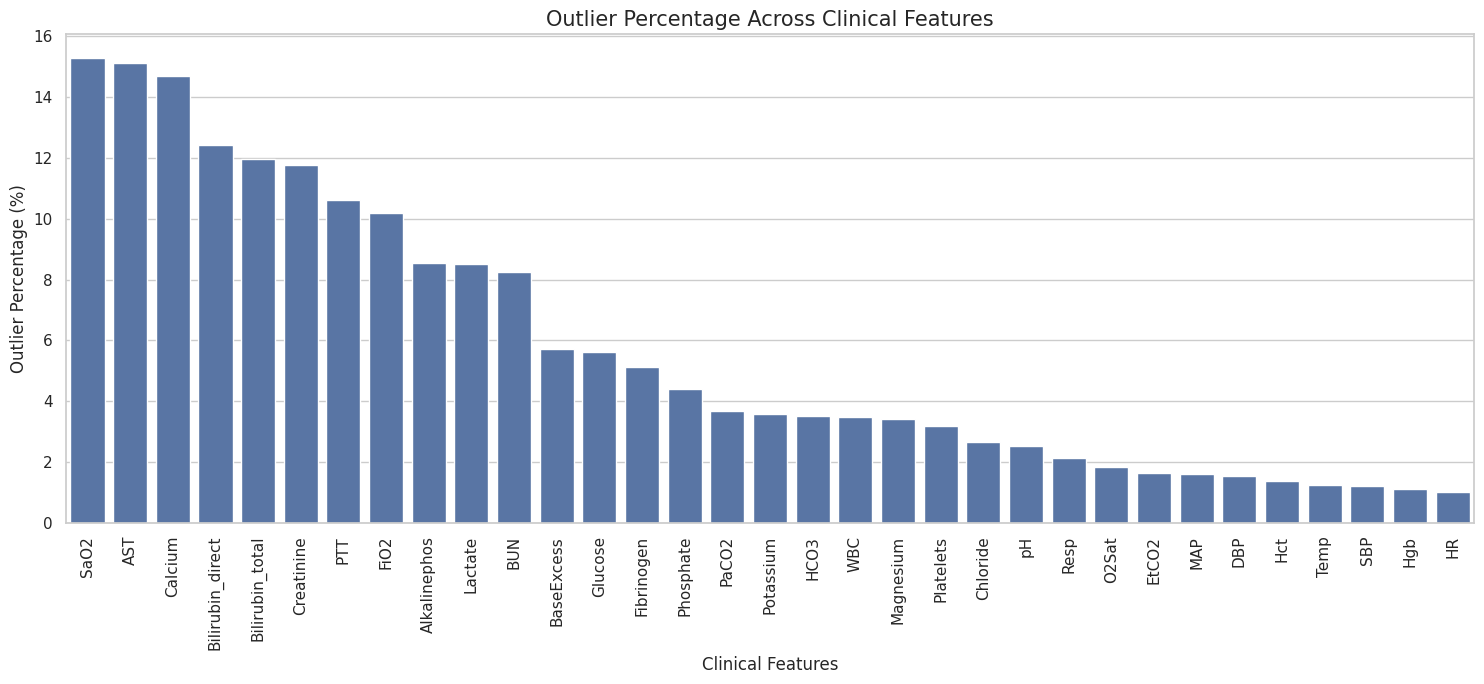

In [148]:
# ==========================================
# STEP 38: OUTLIER PERCENTAGE VISUALIZATION
# ==========================================

outlier_plot_data = iqr_report.sort_values(
    "Outlier_Percentage",
    ascending=False
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=outlier_plot_data,
    x="Feature",
    y="Outlier_Percentage"
)

plt.title(
    "Outlier Percentage Across Clinical Features",
    fontsize=15
)

plt.xlabel("Clinical Features")

plt.ylabel("Outlier Percentage (%)")

plt.xticks(rotation=90)

plt.tight_layout()

plt.show()

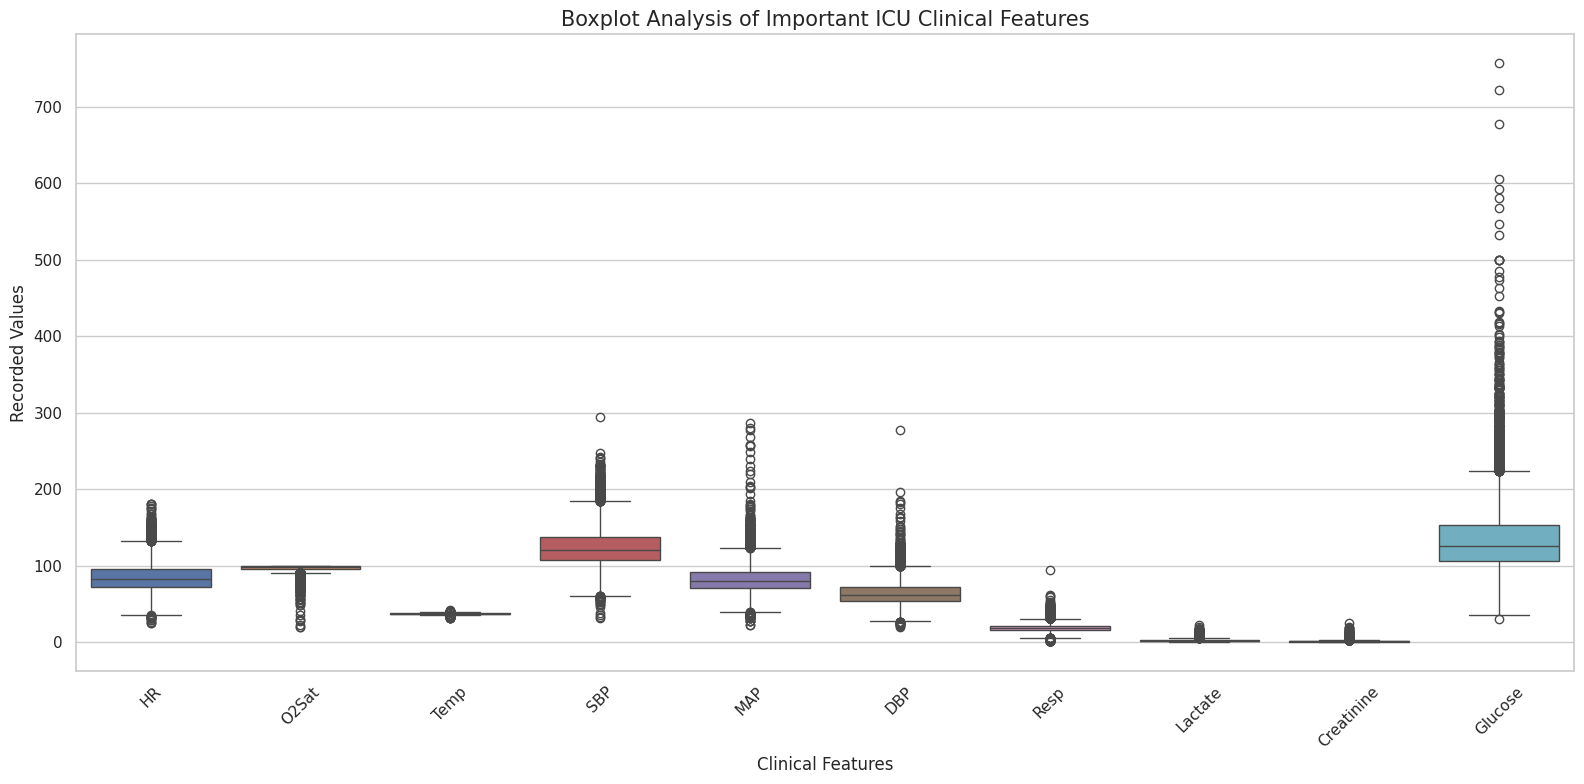

In [149]:
# ==========================================
# STEP 39: CLINICAL FEATURE BOXPLOTS
# ==========================================

important_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp",
    "Lactate",
    "Creatinine",
    "Glucose"
]

# Keep only available features
important_features = [
    col for col in important_features
    if col in df.columns
]

# Use a sample for faster visualization
plot_data = df[important_features].sample(
    n=min(50000, len(df)),
    random_state=42
)

plt.figure(figsize=(16, 8))

sns.boxplot(
    data=plot_data
)

plt.title(
    "Boxplot Analysis of Important ICU Clinical Features",
    fontsize=15
)

plt.xlabel("Clinical Features")

plt.ylabel("Recorded Values")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

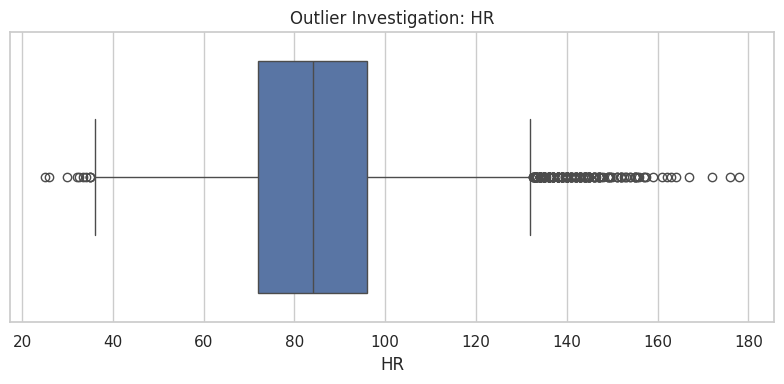

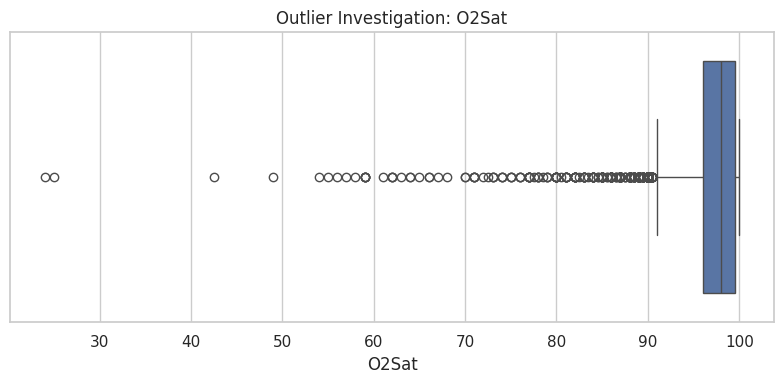

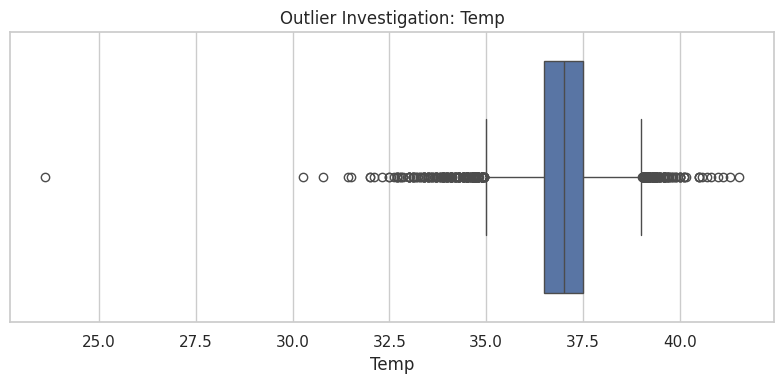

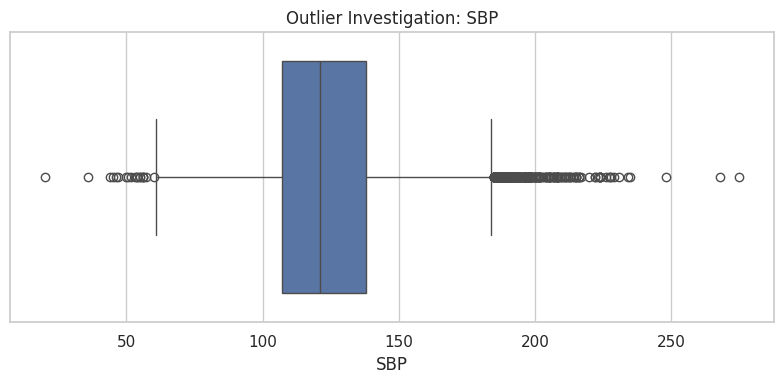

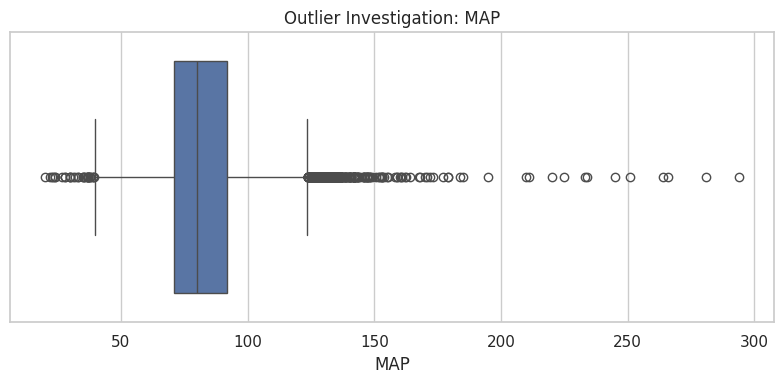

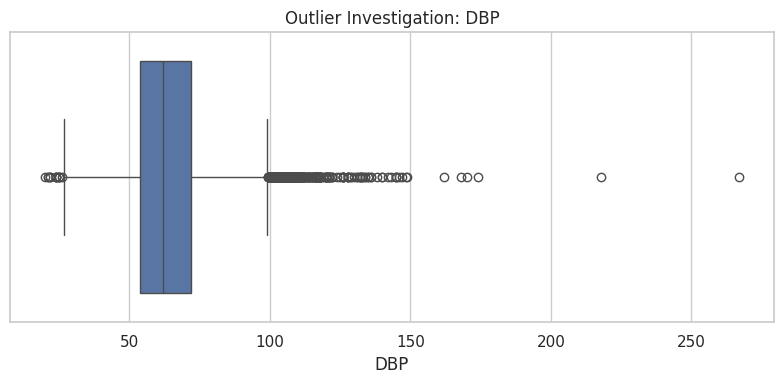

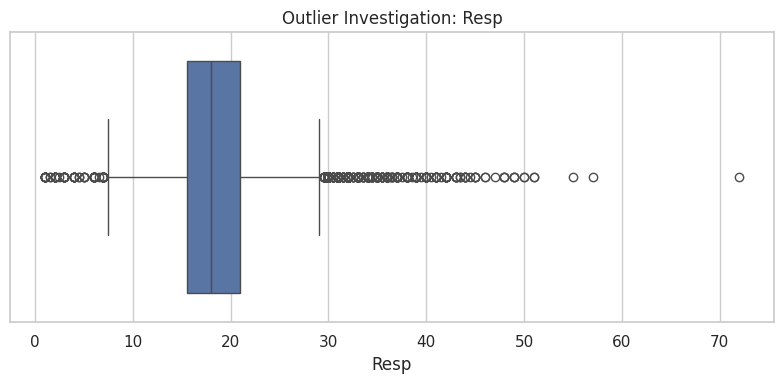

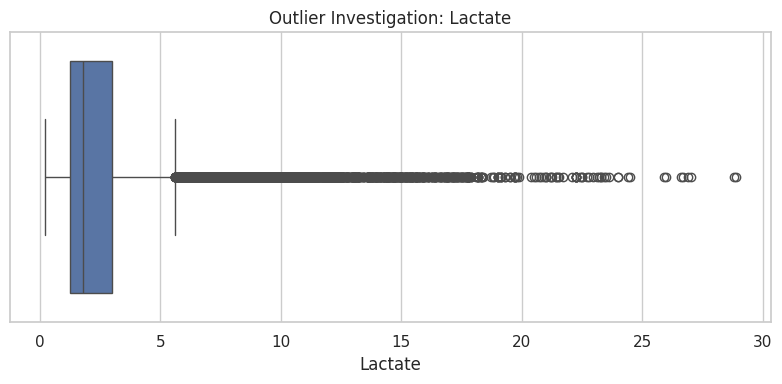

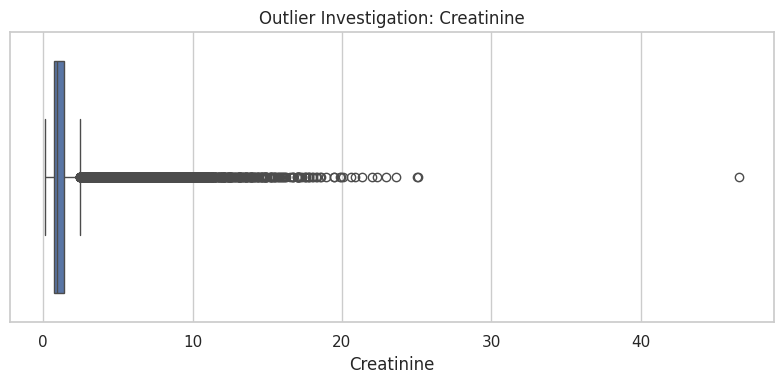

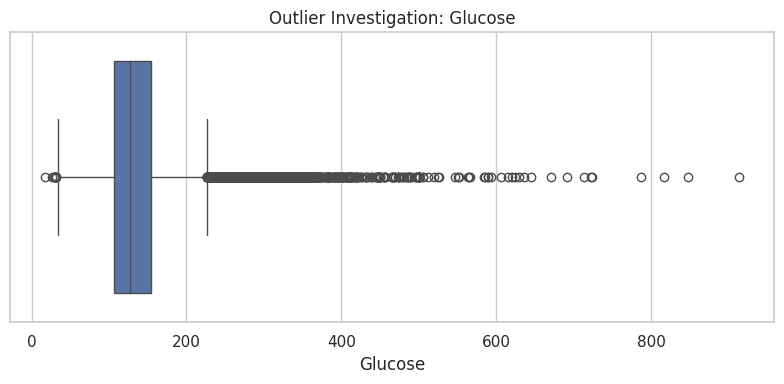

In [150]:
# ==========================================
# STEP 40: INDIVIDUAL FEATURE BOXPLOTS
# ==========================================

for feature in important_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[feature].dropna().sample(
            n=min(
                30000,
                df[feature].notna().sum()
            ),
            random_state=42
        )
    )

    plt.title(
        f"Outlier Investigation: {feature}"
    )

    plt.xlabel(feature)

    plt.tight_layout()

    plt.show()

In [151]:
# ==========================================
# STEP 41: INVESTIGATE EXTREME OBSERVATIONS
# ==========================================

top_outlier_features = (
    iqr_report
    .sort_values(
        "Outlier_Percentage",
        ascending=False
    )
    .head(5)["Feature"]
    .tolist()
)

print("Top Five Features with Highest IQR Outlier Percentage:")

print(top_outlier_features)

for feature in top_outlier_features:

    lower = iqr_report.loc[
        iqr_report["Feature"] == feature,
        "Lower_Bound"
    ].iloc[0]

    upper = iqr_report.loc[
        iqr_report["Feature"] == feature,
        "Upper_Bound"
    ].iloc[0]

    extreme_values = df[
        (df[feature] < lower) |
        (df[feature] > upper)
    ][
        ["Patient_ID", "ICULOS", feature, "SepsisLabel"]
    ]

    print(f"\nExtreme observations for {feature}:")

    display(
        extreme_values.head(10)
    )

Top Five Features with Highest IQR Outlier Percentage:
['SaO2', 'AST', 'Calcium', 'Bilirubin_direct', 'Bilirubin_total']

Extreme observations for SaO2:


,Patient_ID,ICULOS,SaO2,SepsisLabel
387,011768,2,71.0,0
410,011768,25,67.0,0
419,011768,34,62.0,0
502,012878,4,66.0,0
921,010019,6,78.0,0
931,010019,16,74.0,0
1179,010803,9,57.0,0
1189,010803,19,65.0,0
1199,010803,29,56.0,0
1304,004090,3,66.0,0



Extreme observations for AST:


,Patient_ID,ICULOS,AST,SepsisLabel
901,010611,34,1770.0,0
997,011021,3,270.0,0
1002,011021,8,462.0,0
1015,011021,21,1722.0,0
1029,011021,35,1506.0,0
1043,001524,8,394.0,0
1169,004881,31,582.0,0
1310,004090,9,7303.0,0
1316,004090,15,5704.0,0
1324,004090,23,3746.0,0



Extreme observations for Calcium:


,Patient_ID,ICULOS,Calcium,SepsisLabel
583,007316,38,10.5,0
997,011021,3,17.0,0
1029,011021,35,12.9,0
1310,004090,9,13.4,0
1316,004090,15,11.8,0
1324,004090,23,10.3,0
1440,018858,15,10.9,0
4821,006499,5,11.0,0
5127,018850,5,11.4,0
5141,018850,19,11.8,0



Extreme observations for Bilirubin_direct:


,Patient_ID,ICULOS,Bilirubin_direct,SepsisLabel
1310,004090,9,4.6,0
15404,004833,4,7.8,0
28635,013615,7,5.3,0
34476,019007,33,9.9,0
34477,019007,34,9.9,0
34645,019007,202,12.8,1
37040,008672,3,4.9,0
40262,004412,29,5.8,0
40263,004412,30,5.8,0
46155,013742,38,11.2,0



Extreme observations for Bilirubin_total:


,Patient_ID,ICULOS,Bilirubin_total,SepsisLabel
1002,011021,8,4.8,0
1015,011021,21,3.6,0
1029,011021,35,3.8,0
1169,004881,31,20.2,0
1310,004090,9,6.2,0
1316,004090,15,4.3,0
1958,012236,4,4.5,0
2852,017444,2,4.7,0
2862,017444,12,6.8,0
2872,017444,22,3.9,0


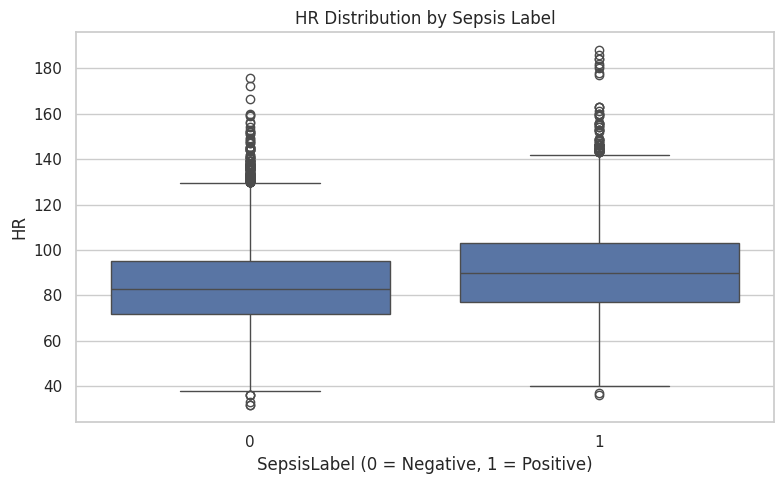

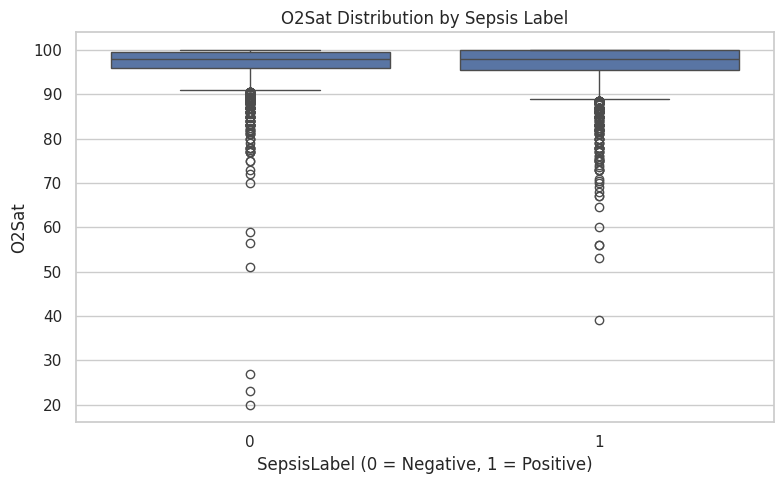

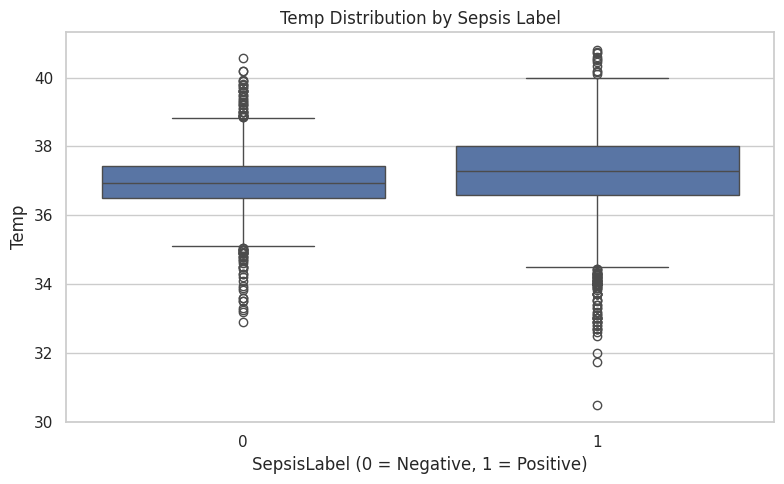

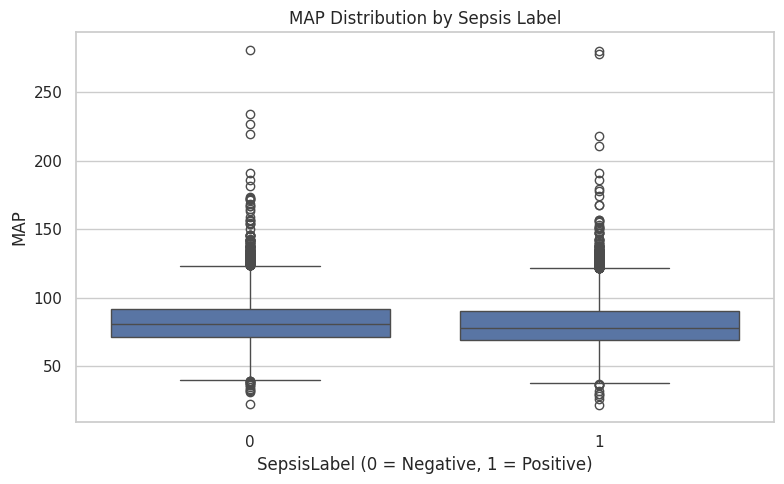

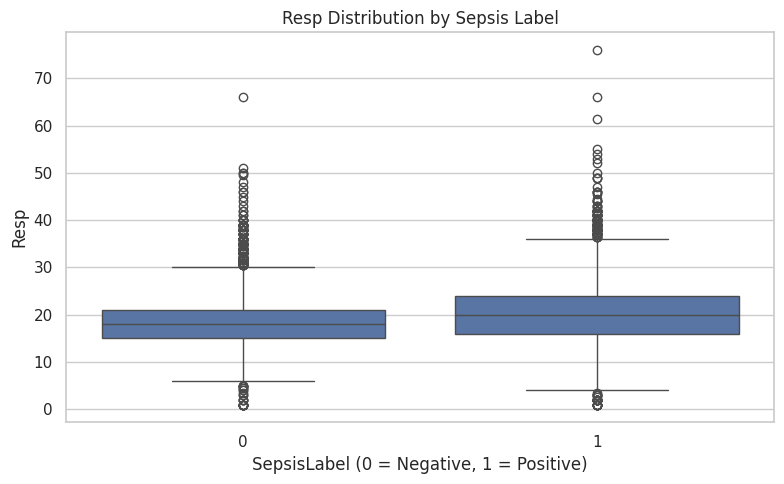

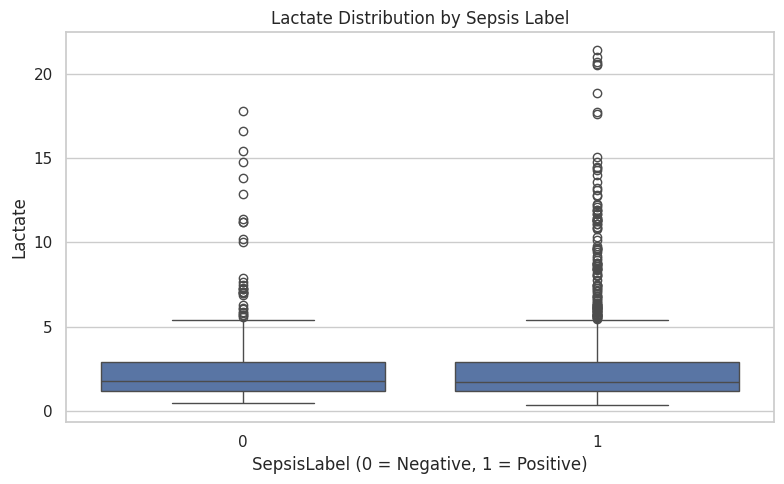

In [152]:
## 5.1 Comparison of Clinical Distributions by SepsisLabel

'''This section investigates the distribution of clinical
measurements across positive and negative sepsis labels.

The objective is to understand whether unusual clinical
measurements show different distribution patterns between
the two labelled groups.

These comparisons are descriptive and do not establish
causation or predictive importance.'''

# ==========================================
# STEP 42: SEPSIS LABEL GROUP COMPARISON
# ==========================================

comparison_features = [
    "HR",
    "O2Sat",
    "Temp",
    "MAP",
    "Resp",
    "Lactate"
]

comparison_features = [
    col for col in comparison_features
    if col in df.columns
]

# Take a sample from each label group
group_samples = []

for label in [0, 1]:

    group = df[
        df["SepsisLabel"] == label
    ]

    group = group.sample(
        n=min(15000, len(group)),
        random_state=42
    )

    group_samples.append(group)

comparison_df = pd.concat(
    group_samples,
    ignore_index=True
)

for feature in comparison_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=comparison_df,
        x="SepsisLabel",
        y=feature
    )

    plt.title(
        f"{feature} Distribution by Sepsis Label"
    )

    plt.xlabel("SepsisLabel (0 = Negative, 1 = Positive)")

    plt.ylabel(feature)

    plt.tight_layout()

    plt.show()

In [153]:
# ==========================================
# STEP 43: OUTLIER INVESTIGATION SUMMARY
# ==========================================

outlier_summary = iqr_report[
    [
        "Feature",
        "Outlier_Count",
        "Outlier_Percentage",
        "Lower_Bound",
        "Upper_Bound"
    ]
].copy()

outlier_summary = outlier_summary.sort_values(
    "Outlier_Count",
    ascending=False
)

display(outlier_summary)

print(
    "\nTotal Feature-wise Outlier Counts:",
    outlier_summary["Outlier_Count"].sum()
)

,Feature,Outlier_Count,Outlier_Percentage,Lower_Bound,Upper_Bound
6,Resp,27855,2.120065,5.250,31.250
1,O2Sat,24782,1.836419,90.750,104.750
4,MAP,21894,1.611109,39.500,123.500
5,DBP,16296,1.529199,27.000,99.000
3,SBP,15842,1.194771,60.500,184.500
21,Glucose,14948,5.629793,35.500,223.500
0,HR,14032,1.003138,36.750,130.750
17,Calcium,13435,14.710230,6.200,10.200
10,FiO2,13191,10.196730,0.100,0.900
19,Creatinine,11139,11.772850,-0.395,2.525



Total Feature-wise Outlier Counts: 251547


In [154]:
# ==========================================
# STEP 44: SAVE OUTLIER REPORTS
# ==========================================

OUTPUT_PATH = (
    "/content/drive/MyDrive/SepsisShield_Phase2/"
    "outputs/preprocessing"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Save complete IQR analysis
iqr_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "iqr_outlier_analysis.csv"
    ),
    index=False
)

# Save outlier summary
outlier_summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "outlier_investigation_summary.csv"
    ),
    index=False
)

print("Outlier investigation reports saved successfully!")

Outlier investigation reports saved successfully!


In [155]:
# 6. Data Transformation and Feature Preparation

'''Data transformation involves converting dataset variables
into appropriate formats for subsequent analysis and
machine learning.

This section investigates:

1. Redundant and unnecessary columns.
2. Numerical data type consistency.
3. Categorical feature representation.
4. Constant and low-variation columns.
5. Numerical feature scaling requirements.
6. Preservation of important identifiers and target labels.

The original dataset will remain unchanged.

Rolling feature engineering and PCA are excluded from
this stage because they are handled separately.'''
# ==========================================
# STEP 46: REDUNDANT COLUMN INVESTIGATION
# ==========================================

print("TOTAL DATASET COLUMNS:", len(df.columns))

print("\nALL COLUMN NAMES:")

for col in df.columns:
    print(col)

# Identify potential index columns
unnamed_columns = [
    col for col in df.columns
    if col.startswith("Unnamed")
]

print("\nPotential Redundant Columns:")

print(unnamed_columns)

for col in unnamed_columns:

    print(f"\nInvestigating: {col}")

    print("Unique Values:", df[col].nunique())

    print("Sample Values:")

    display(df[col].head(10))


TOTAL DATASET COLUMNS: 44

ALL COLUMN NAMES:
Unnamed: 0
Hour
HR
O2Sat
Temp
SBP
MAP
DBP
Resp
EtCO2
BaseExcess
HCO3
FiO2
pH
PaCO2
SaO2
AST
BUN
Alkalinephos
Calcium
Chloride
Creatinine
Bilirubin_direct
Glucose
Lactate
Magnesium
Phosphate
Potassium
Bilirubin_total
TroponinI
Hct
Hgb
PTT
WBC
Fibrinogen
Platelets
Age
Gender
Unit1
Unit2
HospAdmTime
ICULOS
SepsisLabel
Patient_ID

Potential Redundant Columns:
['Unnamed: 0']

Investigating: Unnamed: 0
Unique Values: 336
Sample Values:


,Unnamed: 0
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [156]:
# ==========================================
# STEP 47: DUPLICATE COLUMN NAME CHECK
# ==========================================

duplicate_column_names = df.columns[
    df.columns.duplicated()
].tolist()

print("Duplicate Column Names:")

print(duplicate_column_names)

if len(duplicate_column_names) == 0:

    print("\nNo duplicate column names found.")

else:

    print("\nDuplicate column names require investigation.")

Duplicate Column Names:
[]

No duplicate column names found.


In [157]:
# ==========================================
# STEP 48: NUMERICAL DATA TYPE VALIDATION
# ==========================================

numeric_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("NUMERICAL COLUMNS:")

print(numeric_columns)

print("\nNON-NUMERICAL COLUMNS:")

print(categorical_columns)

print("\nNumerical Column Count:",
      len(numeric_columns))

print("Non-Numerical Column Count:",
      len(categorical_columns))

NUMERICAL COLUMNS:
['Unnamed: 0', 'Hour', 'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel']

NON-NUMERICAL COLUMNS:
['Patient_ID']

Numerical Column Count: 43
Non-Numerical Column Count: 1


In [158]:
# ==========================================
# STEP 49: CATEGORICAL FEATURE INVESTIGATION
# ==========================================

categorical_features = [
    "Gender",
    "Unit1",
    "Unit2"
]

categorical_features = [
    col for col in categorical_features
    if col in df.columns
]

for feature in categorical_features:

    print("\nFeature:", feature)

    print("Data Type:", df[feature].dtype)

    print("Unique Values:")

    print(df[feature].value_counts(
        dropna=False
    ))

    print(
        "Missing Percentage:",
        df[feature].isnull().mean() * 100
    )


Feature: Gender
Data Type: int64
Unique Values:
Gender
1    868103
0    684107
Name: count, dtype: int64
Missing Percentage: 0.0

Feature: Unit1
Data Type: float64
Unique Values:
Unit1
NaN    611960
0.0    473349
1.0    466901
Name: count, dtype: int64
Missing Percentage: 39.42507779230903

Feature: Unit2
Data Type: float64
Unique Values:
Unit2
NaN    611960
1.0    473349
0.0    466901
Name: count, dtype: int64
Missing Percentage: 39.42507779230903


In [159]:
# ==========================================
# STEP 50: CONSTANT COLUMN INVESTIGATION
# ==========================================

constant_columns = []

for col in df.columns:

    unique_count = df[col].nunique(
        dropna=False
    )

    if unique_count <= 1:

        constant_columns.append(col)

print("Constant Columns:")

print(constant_columns)

print(
    "\nTotal Constant Columns:",
    len(constant_columns)
)

Constant Columns:
[]

Total Constant Columns: 0


In [160]:
# ==========================================
# STEP 51: NUMERICAL SCALING INVESTIGATION
# ==========================================

scaling_features = [
    col for col in clinical_features
    if col in df.columns
]

scaling_report = pd.DataFrame({

    "Minimum": df[scaling_features].min(),

    "Maximum": df[scaling_features].max(),

    "Mean": df[scaling_features].mean(),

    "Standard_Deviation": df[scaling_features].std()

})

display(scaling_report)

,Minimum,Maximum,Mean,Standard_Deviation
HR,20.00,280.00,84.581443,17.325242
O2Sat,20.00,100.00,97.193955,2.936924
Temp,20.90,50.00,36.977228,0.770014
SBP,20.00,300.00,123.750465,23.231556
MAP,20.00,300.00,82.400100,16.341750
DBP,20.00,300.00,63.830556,13.956010
Resp,1.00,100.00,18.726498,5.098194
EtCO2,10.00,100.00,32.957657,7.951662
BaseExcess,-32.00,100.00,-0.689919,4.294297
HCO3,0.00,55.00,24.075481,4.376504


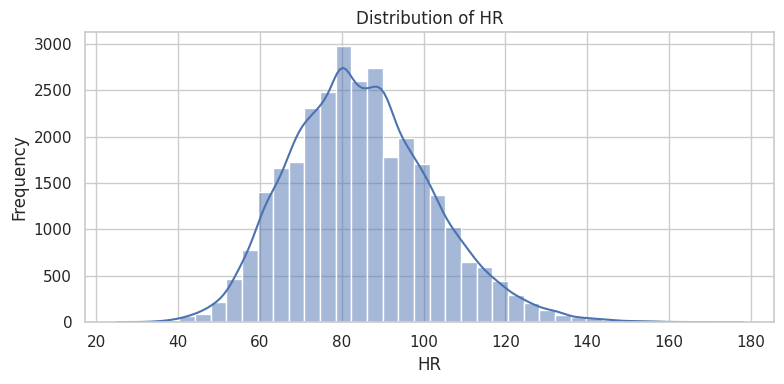

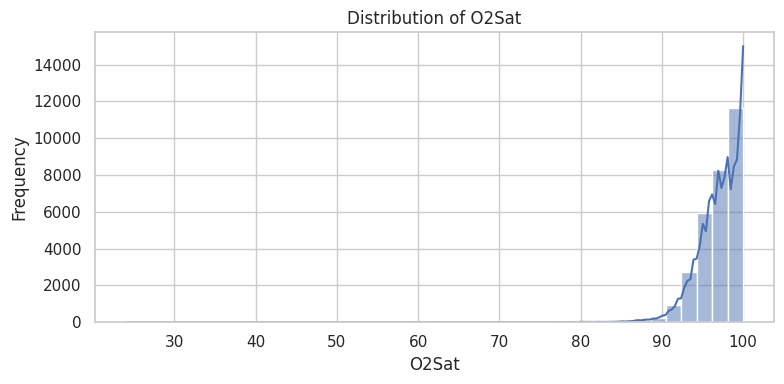

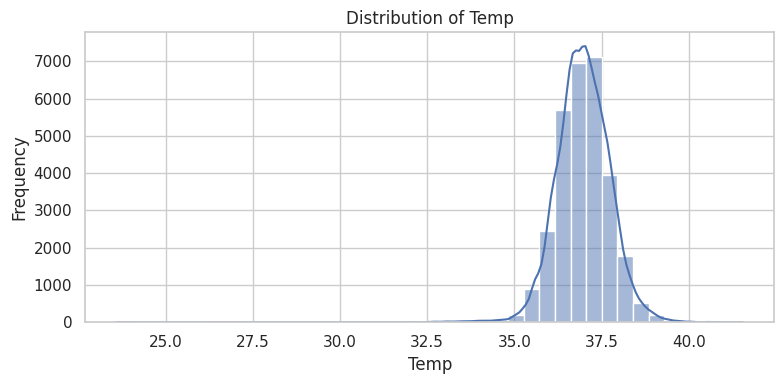

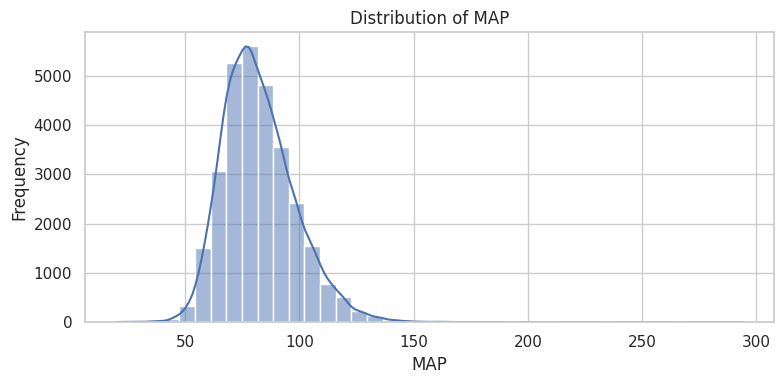

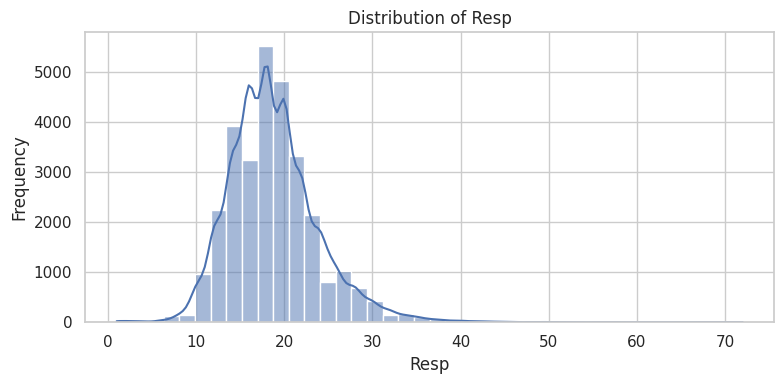

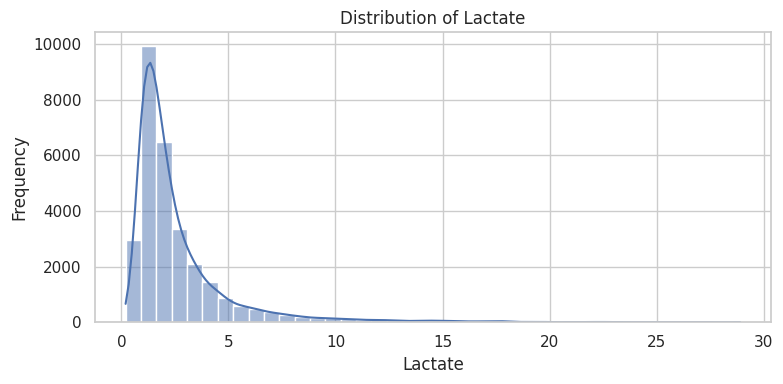

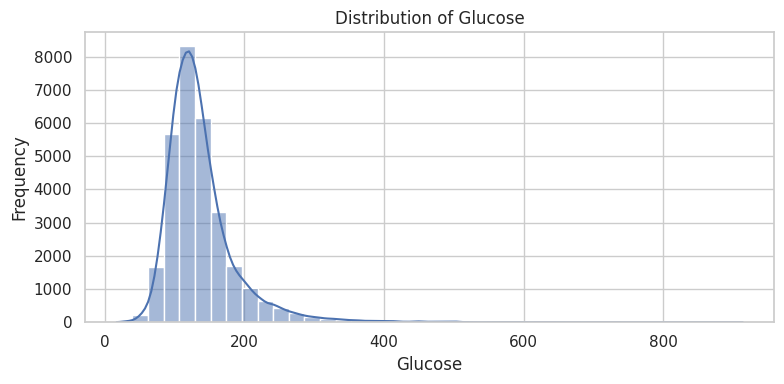

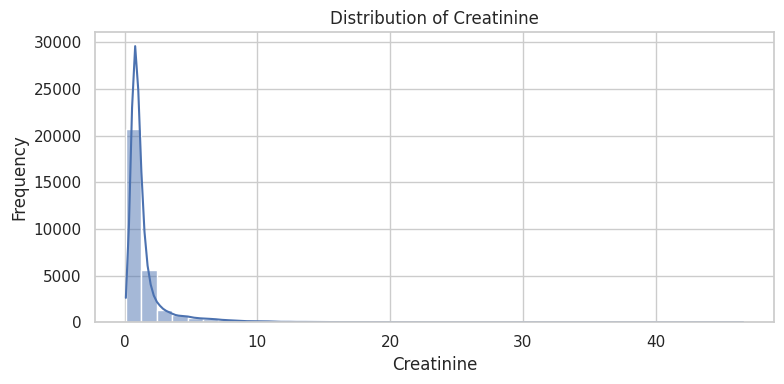

In [161]:
# ==========================================
# STEP 52: NUMERICAL FEATURE DISTRIBUTIONS
# ==========================================

distribution_features = [
    "HR",
    "O2Sat",
    "Temp",
    "MAP",
    "Resp",
    "Lactate",
    "Glucose",
    "Creatinine"
]

distribution_features = [
    col for col in distribution_features
    if col in df.columns
]

for feature in distribution_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[feature].dropna().sample(
            n=min(
                30000,
                df[feature].notna().sum()
            ),
            random_state=42
        ),
        kde=True,
        bins=40
    )

    plt.title(
        f"Distribution of {feature}"
    )

    plt.xlabel(feature)

    plt.ylabel("Frequency")

    plt.tight_layout()

    plt.show()

In [162]:
# ==========================================
# STEP 53: PROTECT IMPORTANT COLUMNS
# ==========================================

protected_columns = [
    "Patient_ID",
    "ICULOS",
    "SepsisLabel"
]

print("Protected Columns:")

for col in protected_columns:

    if col in df.columns:

        print(
            col,
            "- Present and preserved"
        )

    else:

        print(
            col,
            "- WARNING: Missing"
        )

Protected Columns:
Patient_ID - Present and preserved
ICULOS - Present and preserved
SepsisLabel - Present and preserved


In [163]:
# ==========================================
# STEP 54: TRANSFORMATION DECISION REPORT
# ==========================================

transformation_decisions = pd.DataFrame({

    "Feature_Type": [
        "Patient_ID",
        "ICULOS",
        "SepsisLabel",
        "Clinical Measurements",
        "Categorical Features",
        "Potential Unnamed Columns"
    ],

    "Investigation": [
        "Identifier preservation",
        "Numerical data type validation",
        "Binary target validation",
        "Numerical format validation",
        "Category and missingness inspection",
        "Redundancy verification"
    ],

    "Decision": [
        "Preserve as identifier",
        "Preserve as numerical variable",
        "Preserve original labels",
        "Retain numerical measurements",
        "Investigate before encoding",
        "Remove only if verified redundant"
    ]

})

display(transformation_decisions)

,Feature_Type,Investigation,Decision
0,Patient_ID,Identifier preservation,Preserve as identifier
1,ICULOS,Numerical data type validation,Preserve as numerical variable
2,SepsisLabel,Binary target validation,Preserve original labels
3,Clinical Measurements,Numerical format validation,Retain numerical measurements
4,Categorical Features,Category and missingness inspection,Investigate before encoding
5,Potential Unnamed Columns,Redundancy verification,Remove only if verified redundant


In [164]:
# ==========================================
# STEP 55: SAVE TRANSFORMATION REPORTS
# ==========================================

OUTPUT_PATH = (
    "/content/drive/MyDrive/SepsisShield_Phase2/"
    "outputs/preprocessing"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Save categorical investigation
categorical_summary = pd.DataFrame({

    "Feature": categorical_features,

    "Missing_Count": [
        df[col].isnull().sum()
        for col in categorical_features
    ],

    "Unique_Values": [
        df[col].nunique(dropna=False)
        for col in categorical_features
    ]

})

categorical_summary.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "categorical_feature_analysis.csv"
    ),
    index=False
)

# Save numerical scaling report
scaling_report.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "numerical_scaling_analysis.csv"
    )
)

# Save transformation decisions
transformation_decisions.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "transformation_decision_log.csv"
    ),
    index=False
)

print("Transformation reports saved successfully!")

Transformation reports saved successfully!


In [165]:
'''# 7. Final Data Preparation and Export

This section prepares the final dataset for subsequent
feature engineering and machine learning.

The final preparation includes:

1. Reviewing previous data quality findings.
2. Creating a separate processed dataset.
3. Removing only verified redundant columns.
4. Preserving missingness information.
5. Applying justified missing-value handling.
6. Preserving patient identifiers and sepsis labels.
7. Comparing original and processed data quality.
8. Exporting the final dataset in Parquet format.

The original Dataset.csv will never be overwritten.

No rolling feature engineering or PCA will be performed.'''

# ==========================================
# STEP 57: CREATE WORKING DATASET
# ==========================================

processed_df = df.copy()

print("Working dataset created successfully!")

print("Original Dataset Shape:", df.shape)

print("Working Dataset Shape:", processed_df.shape)

print(
    "Original Dataset Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Working Dataset Missing Values:",
    processed_df.isnull().sum().sum()
)

Working dataset created successfully!
Original Dataset Shape: (1552210, 44)
Working Dataset Shape: (1552210, 44)
Original Dataset Missing Values: 43512155
Working Dataset Missing Values: 43512155


In [191]:
# ==========================================
# STEP 58: REDUNDANT COLUMN REMOVAL
# ==========================================

removed_columns = []

for col in processed_df.columns:

    if col.startswith("Unnamed"):

        numeric_values = pd.to_numeric(
            processed_df[col],
            errors="coerce"
        )

        expected_index = np.arange(
            len(processed_df)
        )

        if (
            numeric_values.notna().all()
            and np.array_equal(
                numeric_values.to_numpy(),
                expected_index
            )
        ):

            processed_df.drop(
                columns=[col],
                inplace=True
            )

            removed_columns.append(col)

print("Verified Redundant Columns Removed:")

print(removed_columns)

print("\nFinal Column Count:", len(processed_df.columns))

Verified Redundant Columns Removed:
[]

Final Column Count: 44


In [192]:
processed_df = df.copy()

In [193]:
# ==========================================
# STEP 59: MISSINGNESS INDICATORS
# ==========================================

for col in clinical_features:

    if col in processed_df.columns:

        processed_df[col + "_Missing"] = (
            processed_df[col]
            .isnull()
            .astype("int8")
        )

print("Missingness indicators created!")

print(
    "Total Missingness Indicator Columns:",
    len(clinical_features)
)

display(
    processed_df[
        [
            clinical_features[0],
            clinical_features[0] + "_Missing"
        ]
    ].head()
)

Missingness indicators created!
Total Missingness Indicator Columns: 33


,HR,HR_Missing
0,NaN,1
1,65.0,0
2,78.0,0
3,73.0,0
4,70.0,0


In [198]:
# ==========================================
# STEP 60: FEATURE-SPECIFIC IMPUTATION
# CONTINUITY-AWARE FORWARD FILLING
# ==========================================

import numpy as np

# Select frequently monitored vital signs
vital_features = [
    "HR",
    "O2Sat",
    "Temp",
    "SBP",
    "MAP",
    "DBP",
    "Resp"
]

vital_features = [
    col for col in vital_features
    if col in processed_df.columns
]

# Sort observations chronologically
processed_df = processed_df.sort_values(
    ["Patient_ID", "ICULOS"]
).copy()

# Identify consecutive ICU-hour segments
hour_difference = (
    processed_df.groupby("Patient_ID")["ICULOS"]
    .diff()
)

# Start a new segment whenever ICU hours are not consecutive
processed_df["_segment"] = (
    hour_difference.ne(1) | hour_difference.isna()
).groupby(processed_df["Patient_ID"]).cumsum()

# Apply forward filling only within the same patient
# and consecutive ICU-hour segment
processed_df[vital_features] = (
    processed_df.groupby(
        ["Patient_ID", "_segment"]
    )[vital_features].ffill(limit=3)
)

# Remove temporary segment column
processed_df.drop(columns=["_segment"], inplace=True)

print("Continuity-aware forward filling completed!")

print("\nRemaining Missing Values:")

display(
    processed_df[vital_features].isnull().sum()
)

Continuity-aware forward filling completed!

Remaining Missing Values:


,0
HR,48414
O2Sat,64853
Temp,264835
SBP,95009
MAP,65587
DBP,382607
Resp,83713


In [199]:
print("FORWARD-FILLING VERIFICATION")

display(
    processed_df[vital_features].isnull().sum()
)

print("\nOriginal missing values:")

display(
    df[vital_features].isnull().sum()
)

FORWARD-FILLING VERIFICATION


,0
HR,48414
O2Sat,64853
Temp,264835
SBP,95009
MAP,65587
DBP,382607
Resp,83713



Original missing values:


,0
HR,153399
O2Sat,202736
Temp,1026984
SBP,226265
MAP,193270
DBP,486554
Resp,238335


In [189]:
print("UPDATED MISSING VALUES AFTER IMPUTATION")

display(
    processed_df[vital_features].isnull().sum()
)

UPDATED MISSING VALUES AFTER IMPUTATION


,0
HR,48414
O2Sat,64853
Temp,264835
SBP,95009
MAP,65587
DBP,382607
Resp,83713


In [169]:
# ==========================================
# STEP 61: IMPORTANT COLUMN VALIDATION
# ==========================================

protected_columns = [
    "Patient_ID",
    "ICULOS",
    "SepsisLabel"
]

for col in protected_columns:

    print(
        col,
        "Present:",
        col in processed_df.columns
    )

# Check patient count
print(
    "\nOriginal Patient Count:",
    df["Patient_ID"].nunique()
)

print(
    "Processed Patient Count:",
    processed_df["Patient_ID"].nunique()
)

# Check target labels
print("\nOriginal SepsisLabel Distribution:")

display(
    df["SepsisLabel"].value_counts().sort_index()
)

print("\nProcessed SepsisLabel Distribution:")

display(
    processed_df["SepsisLabel"].value_counts().sort_index()
)

Patient_ID Present: True
ICULOS Present: True
SepsisLabel Present: True

Original Patient Count: 40336
Processed Patient Count: 40336

Original SepsisLabel Distribution:


,count
SepsisLabel,
0,1524294
1,27916



Processed SepsisLabel Distribution:


,count
SepsisLabel,
0,1524294
1,27916


In [170]:
# ==========================================
# STEP 62: DATA QUALITY COMPARISON
# ==========================================

quality_comparison = pd.DataFrame({

    "Original Dataset": [

        df.shape[0],

        df.shape[1],

        df.isnull().sum().sum(),

        df.duplicated().sum(),

        df["Patient_ID"].nunique()

    ],

    "Processed Dataset": [

        processed_df.shape[0],

        processed_df.shape[1],

        processed_df.isnull().sum().sum(),

        processed_df.duplicated().sum(),

        processed_df["Patient_ID"].nunique()

    ]

}, index=[

    "Total Rows",

    "Total Columns",

    "Total Missing Values",

    "Complete Duplicate Rows",

    "Unique Patients"

])

display(quality_comparison)

,Original Dataset,Processed Dataset
Total Rows,1552210,1552210
Total Columns,44,77
Total Missing Values,43512155,41989630
Complete Duplicate Rows,0,0
Unique Patients,40336,40336


In [171]:
# ==========================================
# STEP 63: FEATURE-WISE COMPARISON
# ==========================================

feature_comparison = pd.DataFrame({

    "Original_Missing": df[clinical_features].isnull().sum(),

    "Processed_Missing": processed_df[
        clinical_features
    ].isnull().sum()

})

feature_comparison["Missing_Values_Reduced"] = (
    feature_comparison["Original_Missing"] -
    feature_comparison["Processed_Missing"]
)

display(
    feature_comparison.sort_values(
        "Missing_Values_Reduced",
        ascending=False
    )
)

,Original_Missing,Processed_Missing,Missing_Values_Reduced
Temp,1026984,264835,762149
Resp,238335,83713,154622
O2Sat,202736,64853,137883
SBP,226265,95009,131256
MAP,193270,65587,127683
HR,153399,48414,104985
DBP,486554,382607,103947
EtCO2,1494574,1494574,0
BaseExcess,1468065,1468065,0
HCO3,1487182,1487182,0


In [197]:
# CHECK CURRENT DATA BEFORE EXPORT

print("PROCESSED DATAFRAME CHECK")

display(
    processed_df[vital_features].isnull().sum()
)

print("\nOriginal DataFrame Check")

display(
    df[vital_features].isnull().sum()
)

PROCESSED DATAFRAME CHECK


,0
HR,153399
O2Sat,202736
Temp,1026984
SBP,226265
MAP,193270
DBP,486554
Resp,238335



Original DataFrame Check


,0
HR,153399
O2Sat,202736
Temp,1026984
SBP,226265
MAP,193270
DBP,486554
Resp,238335


In [172]:
%pip install pyarrow

In [200]:
# ==========================================
# STEP 64: PARQUET EXPORT
# ==========================================

OUTPUT_PATH = (
    "/content/drive/MyDrive/SepsisShield_Phase2/"
    "outputs/preprocessing"
)

os.makedirs(OUTPUT_PATH, exist_ok=True)

PARQUET_PATH = os.path.join(
    OUTPUT_PATH,
    "SepsisShield_Cleaned_Dataset.parquet"
)

processed_df.to_parquet(
    PARQUET_PATH,
    index=False,
    compression="snappy"
)

print("Dataset exported successfully!")

print("Saved Location:")

print(PARQUET_PATH)

print("\nFinal Dataset Shape:")

print(processed_df.shape)

Dataset exported successfully!
Saved Location:
/content/drive/MyDrive/SepsisShield_Phase2/outputs/preprocessing/SepsisShield_Cleaned_Dataset.parquet

Final Dataset Shape:
(1552210, 77)


In [201]:
# ==========================================
# STEP 65: PARQUET VERIFICATION
# ==========================================

verified_df = pd.read_parquet(
    PARQUET_PATH
)

print("PARQUET VERIFICATION")

print("=" * 50)

print("Exported Dataset Shape:", verified_df.shape)

print(
    "Unique Patients:",
    verified_df["Patient_ID"].nunique()
)

print(
    "Missing Values:",
    verified_df.isnull().sum().sum()
)

print(
    "SepsisLabel Values:",
    verified_df["SepsisLabel"].unique()
)

print(
    "Patient_ID Preserved:",
    "Patient_ID" in verified_df.columns
)

print(
    "ICULOS Preserved:",
    "ICULOS" in verified_df.columns
)

print(
    "SepsisLabel Preserved:",
    "SepsisLabel" in verified_df.columns
)

print("\nParquet file verified successfully!")

PARQUET VERIFICATION
Exported Dataset Shape: (1552210, 77)
Unique Patients: 40336
Missing Values: 41989630
SepsisLabel Values: [0 1]
Patient_ID Preserved: True
ICULOS Preserved: True
SepsisLabel Preserved: True

Parquet file verified successfully!


In [175]:
# ==========================================
# STEP 66: PREPROCESSING DECISION LOG
# ==========================================

decision_log = pd.DataFrame([

    {
        "Operation": "Original Dataset",
        "Decision": "Preserved",
        "Reason": "Maintains original clinical information"
    },

    {
        "Operation": "Duplicate Records",
        "Decision": "No removal required",
        "Reason": "No complete duplicates were identified"
    },

    {
        "Operation": "Patient-Hour Duplicates",
        "Decision": "No removal required",
        "Reason": "No duplicate Patient_ID and ICULOS combinations"
    },

    {
        "Operation": "Missingness Indicators",
        "Decision": "Created",
        "Reason": "Preserves information about originally missing measurements"
    },

    {
        "Operation": "Vital Sign Imputation",
        "Decision": "Limited forward filling",
        "Reason": "Maximum three observations within the same patient"
    },

    {
        "Operation": "Laboratory Measurements",
        "Decision": "Missing values retained",
        "Reason": "Avoids artificial imputation of infrequently measured features"
    },

    {
        "Operation": "Outliers",
        "Decision": "Retained",
        "Reason": "Extreme clinical observations may be meaningful"
    },

    {
        "Operation": "Patient_ID",
        "Decision": "Preserved",
        "Reason": "Required for patient-level grouping"
    },

    {
        "Operation": "ICULOS",
        "Decision": "Preserved",
        "Reason": "Required for temporal analysis"
    },

    {
        "Operation": "SepsisLabel",
        "Decision": "Preserved unchanged",
        "Reason": "Original target labels must not be modified"
    },

    {
        "Operation": "Feature Scaling",
        "Decision": "Not performed",
        "Reason": "To be fitted using training data during modelling"

    },

    {
        "Operation": "PCA",
        "Decision": "Not performed",
        "Reason": "Assigned to subsequent feature engineering"

    }

])

display(decision_log)

,Operation,Decision,Reason
0,Original Dataset,Preserved,Maintains original clinical information
1,Duplicate Records,No removal required,No complete duplicates were identified
2,Patient-Hour Duplicates,No removal required,No duplicate Patient_ID and ICULOS combinations
3,Missingness Indicators,Created,Preserves information about originally missing...
4,Vital Sign Imputation,Limited forward filling,Maximum three observations within the same pat...
5,Laboratory Measurements,Missing values retained,Avoids artificial imputation of infrequently m...
6,Outliers,Retained,Extreme clinical observations may be meaningful
7,Patient_ID,Preserved,Required for patient-level grouping
8,ICULOS,Preserved,Required for temporal analysis
9,SepsisLabel,Preserved unchanged,Original target labels must not be modified


In [176]:
# STEP 67: FORWARD-FILL VALIDATION

vital_features = [
    "HR", "O2Sat", "Temp", "SBP",
    "MAP", "DBP", "Resp"
]

print("FORWARD-FILL VALIDATION")
print("=" * 50)

for col in vital_features:

    original_missing = df[col].isna().sum()
    processed_missing = processed_df[col].isna().sum()

    filled = original_missing - processed_missing

    print(f"\nFeature: {col}")
    print("Original missing:", original_missing)
    print("Processed missing:", processed_missing)
    print("Values filled:", filled)

print("\nPatient-hour duplicate check:")

print(
    processed_df.duplicated(
        subset=["Patient_ID", "ICULOS"]
    ).sum()
)

print("\nICULOS missing values:")
print(processed_df["ICULOS"].isna().sum())

FORWARD-FILL VALIDATION

Feature: HR
Original missing: 153399
Processed missing: 48414
Values filled: 104985

Feature: O2Sat
Original missing: 202736
Processed missing: 64853
Values filled: 137883

Feature: Temp
Original missing: 1026984
Processed missing: 264835
Values filled: 762149

Feature: SBP
Original missing: 226265
Processed missing: 95009
Values filled: 131256

Feature: MAP
Original missing: 193270
Processed missing: 65587
Values filled: 127683

Feature: DBP
Original missing: 486554
Processed missing: 382607
Values filled: 103947

Feature: Resp
Original missing: 238335
Processed missing: 83713
Values filled: 154622

Patient-hour duplicate check:
0

ICULOS missing values:
0


In [202]:
# ==========================================
# STEP 68: FINAL DATASET VERIFICATION
# ==========================================

import os
import pandas as pd

print("FINAL SEPSISSHIELD DATASET VERIFICATION")
print("=" * 55)

# Check whether the exported file exists
print("File exists:", os.path.exists(PARQUET_PATH))

# Load exported dataset
final_df = pd.read_parquet(PARQUET_PATH)

print("\nDataset Shape:", final_df.shape)

print("Unique Patients:", final_df["Patient_ID"].nunique())

print("Duplicate Patient-Hour Records:",
      final_df.duplicated(
          subset=["Patient_ID", "ICULOS"]
      ).sum())

print("Missing ICULOS:", final_df["ICULOS"].isna().sum())

print("SepsisLabel Values:",
      sorted(final_df["SepsisLabel"].dropna().unique()))

print("\nMissing Values in Vital Signs:")

display(final_df[vital_features].isnull().sum())

print("\nFinal verification completed!")

FINAL SEPSISSHIELD DATASET VERIFICATION
File exists: True

Dataset Shape: (1552210, 77)
Unique Patients: 40336
Duplicate Patient-Hour Records: 0
Missing ICULOS: 0
SepsisLabel Values: [np.int64(0), np.int64(1)]

Missing Values in Vital Signs:


,0
HR,48414
O2Sat,64853
Temp,264835
SBP,95009
MAP,65587
DBP,382607
Resp,83713



Final verification completed!


In [182]:
# ==========================================
# STEP 69: CHECK CURRENT PROCESSED DATAFRAME
# ==========================================

print("CURRENT PROCESSED DATAFRAME")
print("=" * 45)

print("Dataset Shape:", processed_df.shape)

print("\nCurrent Missing Values:")

display(
    processed_df[vital_features].isnull().sum()
)

CURRENT PROCESSED DATAFRAME
Dataset Shape: (1552210, 77)

Current Missing Values:


,0
HR,48414
O2Sat,64853
Temp,264835
SBP,95009
MAP,65587
DBP,382607
Resp,83713


In [183]:
processed_df = df.copy()

In [184]:
print("REBUILT DATASET CHECK")
print("=" * 45)

display(
    processed_df[vital_features].isnull().sum()
)

REBUILT DATASET CHECK


,0
HR,153399
O2Sat,202736
Temp,1026984
SBP,226265
MAP,193270
DBP,486554
Resp,238335


In [178]:
decision_log.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "preprocessing_decision_log.csv"
    ),
    index=False
)

print("Preprocessing decision log saved successfully!")

Preprocessing decision log saved successfully!


In [203]:
# ==========================================
# STEP 73: MISSINGNESS INDICATOR VALIDATION
# ==========================================

indicator_columns = [
    col for col in clinical_features
    if col in df.columns
    and col + "_Missing" in final_df.columns
]

validation_results = {}

for col in indicator_columns:

    expected = (
        df[col].isnull()
        .astype("int8")
        .sort_index()
    )

    actual = (
        final_df[col + "_Missing"]
        .astype("int8")
        .sort_index()
    )

    validation_results[col] = expected.equals(actual)

print("MISSINGNESS INDICATOR VALIDATION")
print("=" * 50)

print("Total indicators:", len(indicator_columns))
print("Correct indicators:", sum(validation_results.values()))
print("Incorrect indicators:",
      sum(not x for x in validation_results.values()))

print("\nAll indicators correct:",
      all(validation_results.values()))

MISSINGNESS INDICATOR VALIDATION
Total indicators: 33
Correct indicators: 0
Incorrect indicators: 33

All indicators correct: False


In [204]:
# ==========================================
# STEP 74: CORRECTED MISSINGNESS VALIDATION
# ==========================================

import numpy as np

# Sort both datasets using the same patient-hour order
df_sorted = df.sort_values(
    ["Patient_ID", "ICULOS"]
)

final_sorted = final_df.sort_values(
    ["Patient_ID", "ICULOS"]
)

# Confirm that both datasets contain identical patient-hour records
keys_match = (
    df_sorted[["Patient_ID", "ICULOS"]].reset_index(drop=True)
    .equals(
        final_sorted[["Patient_ID", "ICULOS"]].reset_index(drop=True)
    )
)

print("Patient-hour records aligned:", keys_match)

# Validate missingness indicators
correct = 0
incorrect = []

for col in clinical_features:

    indicator = col + "_Missing"

    if indicator not in final_sorted.columns or col not in df_sorted.columns:
        continue

    expected = df_sorted[col].isna().to_numpy(dtype="int8")

    actual = final_sorted[indicator].to_numpy(dtype="int8")

    if np.array_equal(expected, actual):
        correct += 1
    else:
        incorrect.append(col)

print("\nCORRECTED MISSINGNESS VALIDATION")
print("=" * 50)

print("Total indicators checked:", correct + len(incorrect))
print("Correct indicators:", correct)
print("Incorrect indicators:", len(incorrect))
print("Incorrect feature names:", incorrect)

print("\nAll indicators correct:",
      keys_match and len(incorrect) == 0)

Patient-hour records aligned: True

CORRECTED MISSINGNESS VALIDATION
Total indicators checked: 33
Correct indicators: 33
Incorrect indicators: 0
Incorrect feature names: []

All indicators correct: True


In [205]:
# ==========================================
# STEP 75: FINAL PREPROCESSING SUMMARY
# ==========================================

print("SEPSISSHIELD - DATA PREPROCESSING SUMMARY")
print("=" * 60)

print("\nDATASET INFORMATION")
print("Total Records:", final_df.shape[0])
print("Total Features:", final_df.shape[1])
print("Unique Patients:", final_df["Patient_ID"].nunique())

print("\nDATA QUALITY")
print("Duplicate Records:",
      final_df.duplicated().sum())

print("Duplicate Patient-Hour Records:",
      final_df.duplicated(
          subset=["Patient_ID", "ICULOS"]
      ).sum())

print("Missing Patient IDs:",
      final_df["Patient_ID"].isna().sum())

print("Missing ICU Hours:",
      final_df["ICULOS"].isna().sum())

print("\nTARGET VARIABLE")
print(final_df["SepsisLabel"].value_counts())

print("\nMISSINGNESS INDICATORS")
print("Indicators validated:", correct)
print("Total indicators:", correct + len(incorrect))

print("\nFINAL OUTPUT")
print("File:", PARQUET_PATH)

print("\nPREPROCESSING SUMMARY COMPLETED!")

SEPSISSHIELD - DATA PREPROCESSING SUMMARY

DATASET INFORMATION
Total Records: 1552210
Total Features: 77
Unique Patients: 40336

DATA QUALITY
Duplicate Records: 0
Duplicate Patient-Hour Records: 0
Missing Patient IDs: 0
Missing ICU Hours: 0

TARGET VARIABLE
SepsisLabel
0    1524294
1      27916
Name: count, dtype: int64

MISSINGNESS INDICATORS
Indicators validated: 33
Total indicators: 33

FINAL OUTPUT
File: /content/drive/MyDrive/SepsisShield_Phase2/outputs/preprocessing/SepsisShield_Cleaned_Dataset.parquet

PREPROCESSING SUMMARY COMPLETED!
